In [94]:
# %pip install statsmodels

In [95]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import IsolationForest

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

DATA = "../data/final/irrigation_ml_dataset.csv"        # parquet теж ок, але потрібен pyarrow
df = (pd.read_csv(DATA, parse_dates=["timestamp"])
        .sort_values(["field_id", "timestamp"])
        .drop_duplicates(["field_id", "timestamp"])
        .reset_index(drop=True))

SM, ST, AT, AH, AP, PR = ("soil_moisture_sensor", "soil_temperature_sensor",
                          "air_temperature_sensor", "air_humidity_sensor",
                          "air_pressure_sensor", "precipitation_sensor")

Блок 1. Огляд якості та пропусків

In [96]:
print(df.groupby(["field_id", "crop"])["timestamp"].agg(["min", "max", "count"]))   # культура змінюється по роках

overview = df.groupby("field_id").agg(
    rows=("timestamp", "size"),
    sm_missing=(SM, lambda s: s.isna().mean()),
    sm_at_100=(SM, lambda s: (s >= 99.9).mean()),
    sm_same_as_prev=(SM, lambda s: (s == s.shift()).mean()),
    st_min=(ST, "min"), st_max=(ST, "max"),
    batt_min=("battery_voltage", "min"))
print(overview.round(3))

for f, g in df.groupby("field_id"):                # часові розриви
    d = g["timestamp"].diff()
    print(f, pd.DataFrame({"gap_end": g.loc[d > pd.Timedelta("3h"), "timestamp"],
                           "gap_len": d[d > pd.Timedelta("3h")]}))

                                   min        max  count
field_id   crop                                         
field_3334 corn    2025-01-01 01:00:00 2025-10-13   6840
           sorghum 2024-03-07 10:00:00 2024-12-31   7167
field_3335 corn    2024-03-15 12:00:00 2025-10-13  13339
             rows  sm_missing  sm_at_100  sm_same_as_prev  st_min  st_max  batt_min
field_id                                                                           
field_3334  14007       0.064      0.107            0.604   -35.0    47.9       3.7
field_3335  13339       0.326      0.058            0.468   -63.0   197.0       3.5
field_3334                  gap_end         gap_len
7167 2025-01-01 01:00:00 1 days 01:00:00
field_3335                   gap_end          gap_len
20684 2025-01-08 11:00:00 20 days 19:00:00


Блок 2. Де-акумуляція ERA5 та єдине джерело ET0

In [97]:
g_ = df.groupby("field_id")
dt = g_["timestamp"].diff()
h1 = df["timestamp"].dt.hour == 1              # ERA5-Land: накопичення скидається о 01:00

def deaccumulate(col):
    inc = g_[col].diff()
    inc[h1] = df.loc[h1, col]
    inc[(dt != pd.Timedelta("1h")) & ~h1] = np.nan   # не різницюємо через пропуски
    return inc

df["p_era5_mm_h"]   = deaccumulate("era5_tp_mm").clip(lower=0)
df["pet_era5_mm_h"] = (-deaccumulate("era5_pev") * 1000).clip(lower=0)   # m -> mm, знак мінус = випаровування
df = df.copy()

# ERA5 PEV систематично завищує порівняно з Open-Meteo ET0 -> калібруємо коефіцієнтом
ov = df[["pet_era5_mm_h", "openmeteo_et0_fao_evapotranspiration"]].dropna()
k_pet = (ov.iloc[:, 1] * ov.iloc[:, 0]).sum() / (ov.iloc[:, 0] ** 2).sum()
print("corr:", ov.corr().iloc[0, 1].round(3), "| k_pet:", round(k_pet, 3))
df["et0_mm_h"] = df["openmeteo_et0_fao_evapotranspiration"].fillna(k_pet * df["pet_era5_mm_h"])


# СУТО під показники певної культури -----------------------------------------------------++++
# Додайте цей код у кінець Блоку 2

# 1. Параметри культур згідно з таблицями 11 та 12 (FAO-56)
# plant_m та plant_d - орієнтовні дати посіву, які можна замінити на реальні агрономічні дані
fao56_crops = {
    'corn': {
        'L_ini': 30, 'L_dev': 40, 'L_mid': 50, 'L_late': 30, 
        'Kc_ini': 0.30, 'Kc_mid': 1.20, 'Kc_end': 0.35, 
        'plant_m': 5, 'plant_d': 1  # 1 травня
    },
    'sorghum': {
        'L_ini': 20, 'L_dev': 35, 'L_mid': 40, 'L_late': 30, 
        'Kc_ini': 0.30, 'Kc_mid': 1.05, 'Kc_end': 0.55, 
        'plant_m': 5, 'plant_d': 10 # 10 травня
    }
}

def build_kc_curve(row):
    crop = row['crop']
    
    # Якщо культура відсутня або невідома, повертаємо базовий множник 1.0 (залишаємо ET0)
    if pd.isna(crop) or crop not in fao56_crops:
        return 1.0 

    p = fao56_crops[crop]
    
    # Визначаємо дату посіву для поточного року запису
    plant_date = pd.Timestamp(year=row['timestamp'].year, month=p['plant_m'], day=p['plant_d'])
    
    # Синхронізація часових поясів, якщо timestamp їх містить
    if row['timestamp'].tzinfo is not None:
        plant_date = plant_date.tz_localize(row['timestamp'].tzinfo)
        
    days = (row['timestamp'] - plant_date).days

    if days < 0:
        return 0.2  # Голий ґрунт до посіву (поза вегетаційним періодом)

    # Лінійна інтерполяція кривої Kc за фазами росту
    if days <= p['L_ini']:
        return p['Kc_ini']
    
    elif days <= (p['L_ini'] + p['L_dev']):
        return p['Kc_ini'] + ((days - p['L_ini']) / p['L_dev']) * (p['Kc_mid'] - p['Kc_ini'])
        
    elif days <= (p['L_ini'] + p['L_dev'] + p['L_mid']):
        return p['Kc_mid']
        
    elif days <= (p['L_ini'] + p['L_dev'] + p['L_mid'] + p['L_late']):
        return p['Kc_mid'] + ((days - (p['L_ini'] + p['L_dev'] + p['L_mid'])) / p['L_late']) * (p['Kc_end'] - p['Kc_mid'])
        
    else:
        return 0.2  # Зібраний урожай / стерня

# 2. Розрахунок динамічного коефіцієнта (Kc) та фактичного випаровування культури (ETc)
df['Kc'] = df.apply(build_kc_curve, axis=1)
df['etc_mm_h'] = df['et0_mm_h'] * df['Kc']

corr: 0.955 | k_pet: 0.579


Блок 3. Детекція аномалій

In [98]:
def run_len(s):                                   # довжина серії однакових значень
    grp = (s != s.shift()).cumsum()
    return s.groupby(grp).transform("size").where(s.notna())

def hampel(s, win=25, k=5.0, floor=0.5):          # робастні викиди (медіана + MAD)
    med = s.rolling(win, center=True, min_periods=win // 2).median()
    mad = (s - med).abs().rolling(win, center=True, min_periods=win // 2).median()
    return (s - med).abs() > k * np.maximum(1.4826 * mad, floor)

def resid_flag(sensor, ref, win=24 * 7, k=5.0, floor=1.0):   # відхилення від еталону (ERA5)
    r = sensor - ref
    med = r.rolling(win, center=True, min_periods=win // 4).median()
    mad = (r - med).abs().rolling(win, center=True, min_periods=win // 4).median()
    return ((r - med).abs() / np.maximum(1.4826 * mad, floor)) > k

RANGE = {SM: (0, 100), ST: (-15, 50), AT: (-35, 50), AH: (0, 100), AP: (900, 1080)}

def flag_field(g):
    g = g.set_index("timestamp")
    f = pd.DataFrame(index=g.index)
    rain = pd.concat([g[PR], g["p_era5_mm_h"], g["openmeteo_precipitation"]], axis=1).max(axis=1).fillna(0)
    rain6 = rain.rolling(6, min_periods=1).sum() > 0.2          # був дощ за останні 6 год

    for c, (lo, hi) in RANGE.items():
        f[f"rng_{c}"] = (g[c] < lo) | (g[c] > hi)

    sm, d = g[SM], g[SM].diff()
    rl = run_len(sm)
    f["sm_flat_stuck"]      = (rl >= 48) & (sm < 99.9)           # завис НЕ на насиченні
    f["sm_sat_plateau"]     = (rl >= 72) & (sm >= 99.9)          # плато на 100 (інформаційно, не аномалія)
    f["sm_spike"]           = hampel(sm, 25, 5, floor=1.0)
    f["sm_jump_up_no_rain"] = (d > 5) & ~rain6                   # ріст без жодного джерела дощу
    f["sm_drop_fast"]       = d < -10                            # фізично нереальне падіння за 1 год

    f["st_flat"]     = run_len(g[ST]) >= 24
    f["st_vs_era5"]  = resid_flag(g[ST], g["era5_stl1_c"],          floor=1.0)
    f["at_vs_era5"]  = resid_flag(g[AT], g["era5_t2m_c"],           floor=1.5)
    f["ap_vs_era5"]  = resid_flag(g[AP], g["era5_sp_hpa"],          floor=0.5)
    f["ah_vs_era5"]  = resid_flag(g[AH], g["era5_relative_humidity"], floor=8.0)

    f["pr_negative"] = g[PR] < 0
    f["pr_dry_gauge"] = (g[PR] == 0) & (g["p_era5_mm_h"].rolling(3, center=True, min_periods=1).sum() > 3)
    return f

flags = (pd.concat({fid: flag_field(g) for fid, g in df.groupby("field_id")}, names=["field_id"])
           .reset_index())
df = df.merge(flags, on=["field_id", "timestamp"], how="left")

sm_cols = ["rng_" + SM, "sm_flat_stuck", "sm_spike", "sm_jump_up_no_rain", "sm_drop_fast"]
df["anom_sm_any"] = df[sm_cols].any(axis=1) & df[SM].notna()
df["sm_clean"] = df[SM].where(~df["anom_sm_any"])      # у пам'яті; НЕ інтерполюйте таргет без потреби

fcols = [c for c in flags.columns if c not in ("field_id", "timestamp")]
print(df.groupby("field_id")[fcols].mean().T.round(4))   # частка рядків з кожним прапорцем

field_id                     field_3334  field_3335
rng_soil_moisture_sensor         0.0000      0.0000
rng_soil_temperature_sensor      0.0001      0.0038
rng_air_temperature_sensor       0.0000      0.0000
rng_air_humidity_sensor          0.0000      0.0000
rng_air_pressure_sensor          0.0000      0.0000
sm_flat_stuck                    0.0478      0.0505
sm_sat_plateau                   0.0777      0.0000
sm_spike                         0.0015      0.0012
sm_jump_up_no_rain               0.0003      0.0007
sm_drop_fast                     0.0003      0.0017
st_flat                          0.1910      0.0517
st_vs_era5                       0.0019      0.0019
at_vs_era5                       0.0001      0.0000
ap_vs_era5                       0.0000      0.0000
ah_vs_era5                       0.0000      0.0000
pr_negative                      0.0000      0.0000
pr_dry_gauge                     0.0077      0.0065


Багатовимірний Isolation Forest. Він навчається лише на перших 70% часу, щоб не було leakage.

In [99]:
feat = [SM, ST, AT, AH, "d_sm", "d_st"]

def iso_field(g):
    g = g.copy()
    g["d_sm"], g["d_st"] = g[SM].diff(), g[ST].diff()
    X = g[feat].dropna()
    tr = X.iloc[: int(len(X) * 0.7)]                              # тільки «минуле»
    m = IsolationForest(n_estimators=300, random_state=0).fit(tr)
    thr = np.quantile(m.score_samples(tr), 0.01)                  # поріг = 1% найгірших у train
    s = pd.Series(m.score_samples(X), index=X.index)
    return (s < thr).reindex(g.index).fillna(False)

df["anom_iforest"] = pd.concat([iso_field(g) for _, g in df.groupby("field_id")]).sort_index().astype(bool)
print(df.groupby("field_id")["anom_iforest"].mean())

field_id
field_3334    0.016206
field_3335    0.021366
Name: anom_iforest, dtype: float64


Зв'язок аномалій з батареєю та сезонністю.

In [100]:
print(df.groupby(pd.cut(df["battery_voltage"], [0, 3.6, 3.8, 4.0, 4.3]), observed=True)["anom_sm_any"]
        .agg(["mean", "size"]))

monthly = (df.groupby(["field_id", df["timestamp"].dt.to_period("M")])["anom_sm_any"]
             .mean().unstack(0).round(3))
print(monthly)

                     mean   size
battery_voltage                 
(0.0, 3.6]       0.125000     80
(3.6, 3.8]       0.244048    336
(3.8, 4.0]       0.358065   1550
(4.0, 4.3]       0.037776  20145
field_id   field_3334  field_3335
timestamp                        
2024-03         0.000       0.000
2024-04         0.000       0.001
2024-05         0.000       0.000
2024-06         0.000       0.000
2024-07         0.007       0.000
2024-08         0.040       0.258
2024-09         0.122       0.186
2024-10         0.000       0.000
2024-11         0.000       0.000
2024-12         0.107       0.005
2025-01         0.171       0.000
2025-02         0.171       0.438
2025-03         0.000       0.000
2025-04         0.003       0.076
2025-05         0.000       0.000
2025-06         0.000       0.000
2025-07         0.125       0.043
2025-08         0.000       0.000
2025-09         0.221       0.000
2025-10         0.000       0.007


Блок 4. Sensor drift

Дрейф оцінюється як тренд різниці «сенсор − еталон» за добовими медіанами. Використовуються нахил Theil–Sen, тест Кендалла та точка зміни CUSUM.

In [101]:
def drift_report(g, sensor, ref, name, rank=False):
    p = g.set_index("timestamp")[[sensor, ref]].dropna()
    if rank:                                       # різні одиниці (0-100 vs м³/м³) -> порівнюємо перцентилі
        p = p.rank(pct=True)
    daily = (p[sensor] - p[ref]).resample("D").median().dropna()
    t = (daily.index - daily.index[0]).days.values.astype(float)
    sl, _, lo, hi = stats.theilslopes(daily.values, t)
    tau, pv = stats.kendalltau(t, daily.values)
    cs = np.cumsum(daily.values - daily.values.mean())
    return dict(variable=name, n_days=len(daily), median_bias=daily.median(),
                slope_per_30d=sl * 30, ci_lo=lo * 30, ci_hi=hi * 30,
                kendall_p=pv, cusum_changepoint=daily.index[np.argmax(np.abs(cs))].date())

PAIRS = [(ST, "era5_stl1_c",            "soil_temp vs ERA5 stl1 (°C)",            False),
         (AT, "era5_t2m_c",             "air_temp vs ERA5 t2m (°C)",              False),
         (AP, "era5_sp_hpa",            "pressure vs ERA5 sp (hPa)",              False),
         (AH, "era5_relative_humidity", "humidity vs ERA5 RH (%)",                False),
         (SM, "era5_swvl2",             "soil_moisture (pct-rank) vs ERA5 swvl2", True),
         (SM, "smap_sm_rootzone",       "soil_moisture (pct-rank) vs SMAP rootzone", True)]

rows = []
for fid, g in df.groupby("field_id"):
    gg = g.copy()
    gg.loc[gg["anom_sm_any"], SM] = np.nan          # оцінюємо дрейф без очевидних аномалій
    for s, r, n, rk in PAIRS:
        rows.append({"field_id": fid, **drift_report(gg, s, r, n, rk)})
drift = pd.DataFrame(rows)
print(drift.round(3).to_string())

# Контроль сезонності: порівняння одного й того ж місяця між роками.
# Тренд за ~19 місяців легко сплутати з сезонною похибкою глибини сенсора.
tmp = df.assign(resid_st=df[ST] - df["era5_stl1_c"],
                year=df["timestamp"].dt.year, month=df["timestamp"].dt.month)
print(tmp.pivot_table(index=["field_id", "month"], columns="year", values="resid_st", aggfunc="median").round(2))

      field_id                                   variable  n_days  median_bias  slope_per_30d  ci_lo  ci_hi  kendall_p cusum_changepoint
0   field_3334                soil_temp vs ERA5 stl1 (°C)     550        0.078          0.053  0.017  0.089      0.004        2024-10-15
1   field_3334                  air_temp vs ERA5 t2m (°C)     550       -0.600          0.023  0.006  0.039      0.006        2024-10-17
2   field_3334                  pressure vs ERA5 sp (hPa)     554        9.443          0.002 -0.005  0.010      0.517        2024-10-20
3   field_3334                    humidity vs ERA5 RH (%)     550        4.854         -0.254 -0.372 -0.135      0.000        2024-10-14
4   field_3334     soil_moisture (pct-rank) vs ERA5 swvl2     533       -0.031         -0.004 -0.008  0.000      0.055        2025-05-05
5   field_3334  soil_moisture (pct-rank) vs SMAP rootzone     533        0.022          0.009  0.006  0.012      0.000        2024-04-23
6   field_3335                soil_temp v

Як читати результат: дрейфом можна вважати змінну, якщо kendall_p < 0.05, довірчий інтервал нахилу не містить 0 і ефект підтверджується порівнянням «місяць до місяця» між роками.

Блок 5. Візуалізація

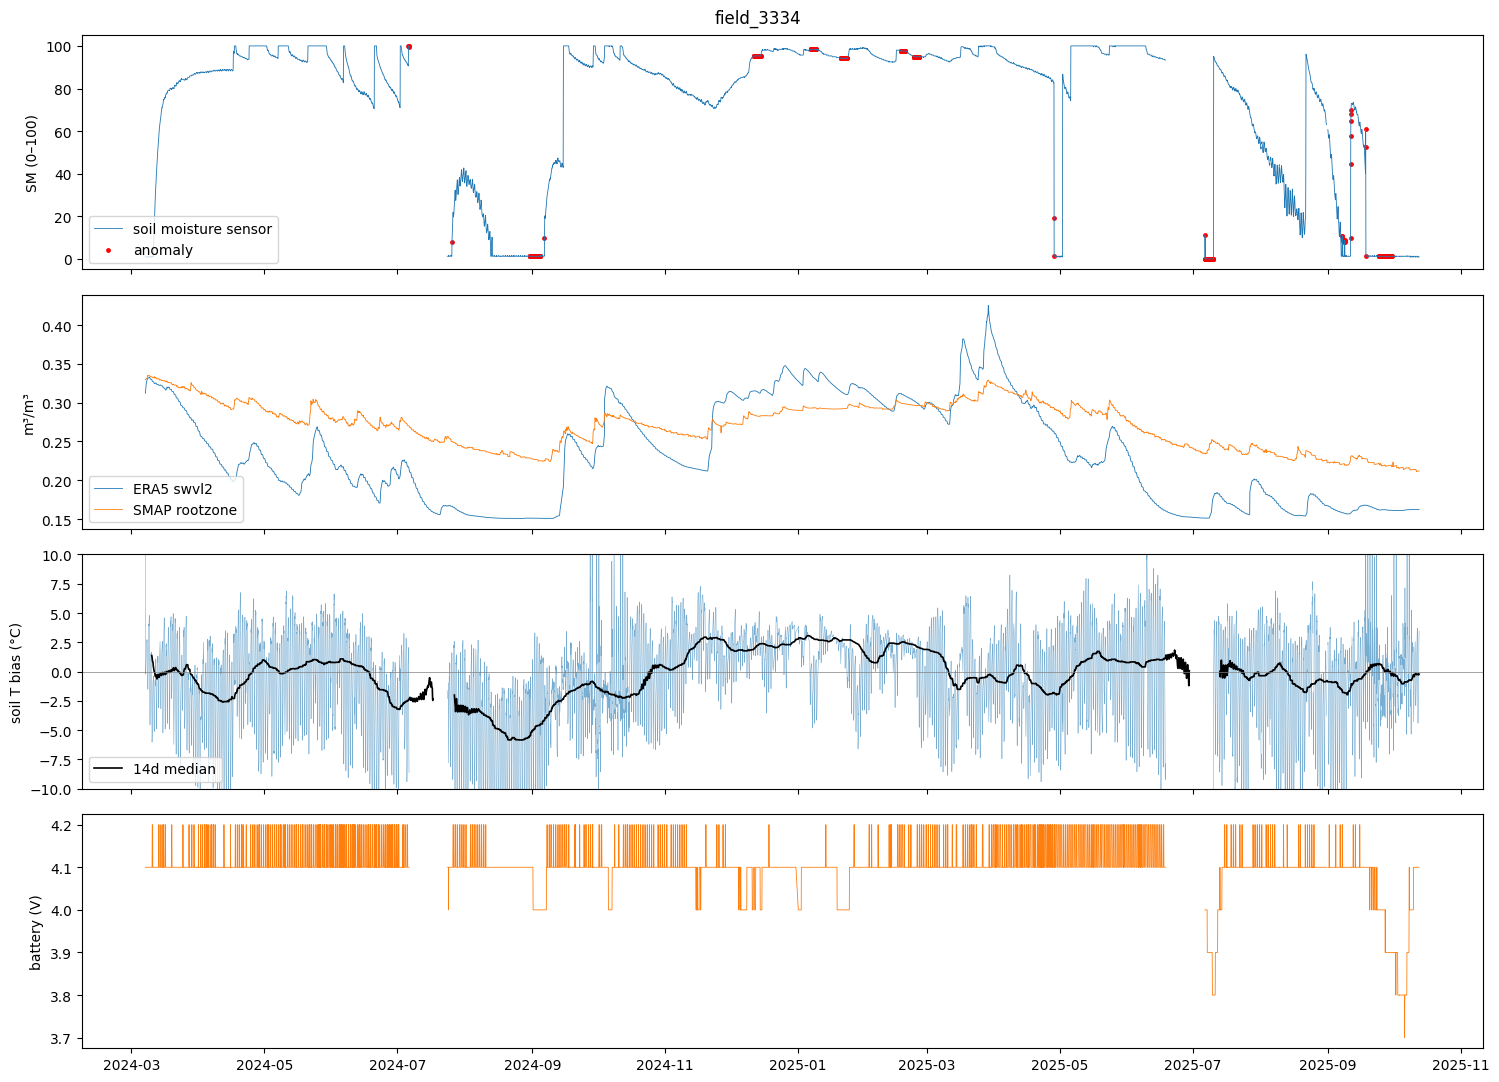

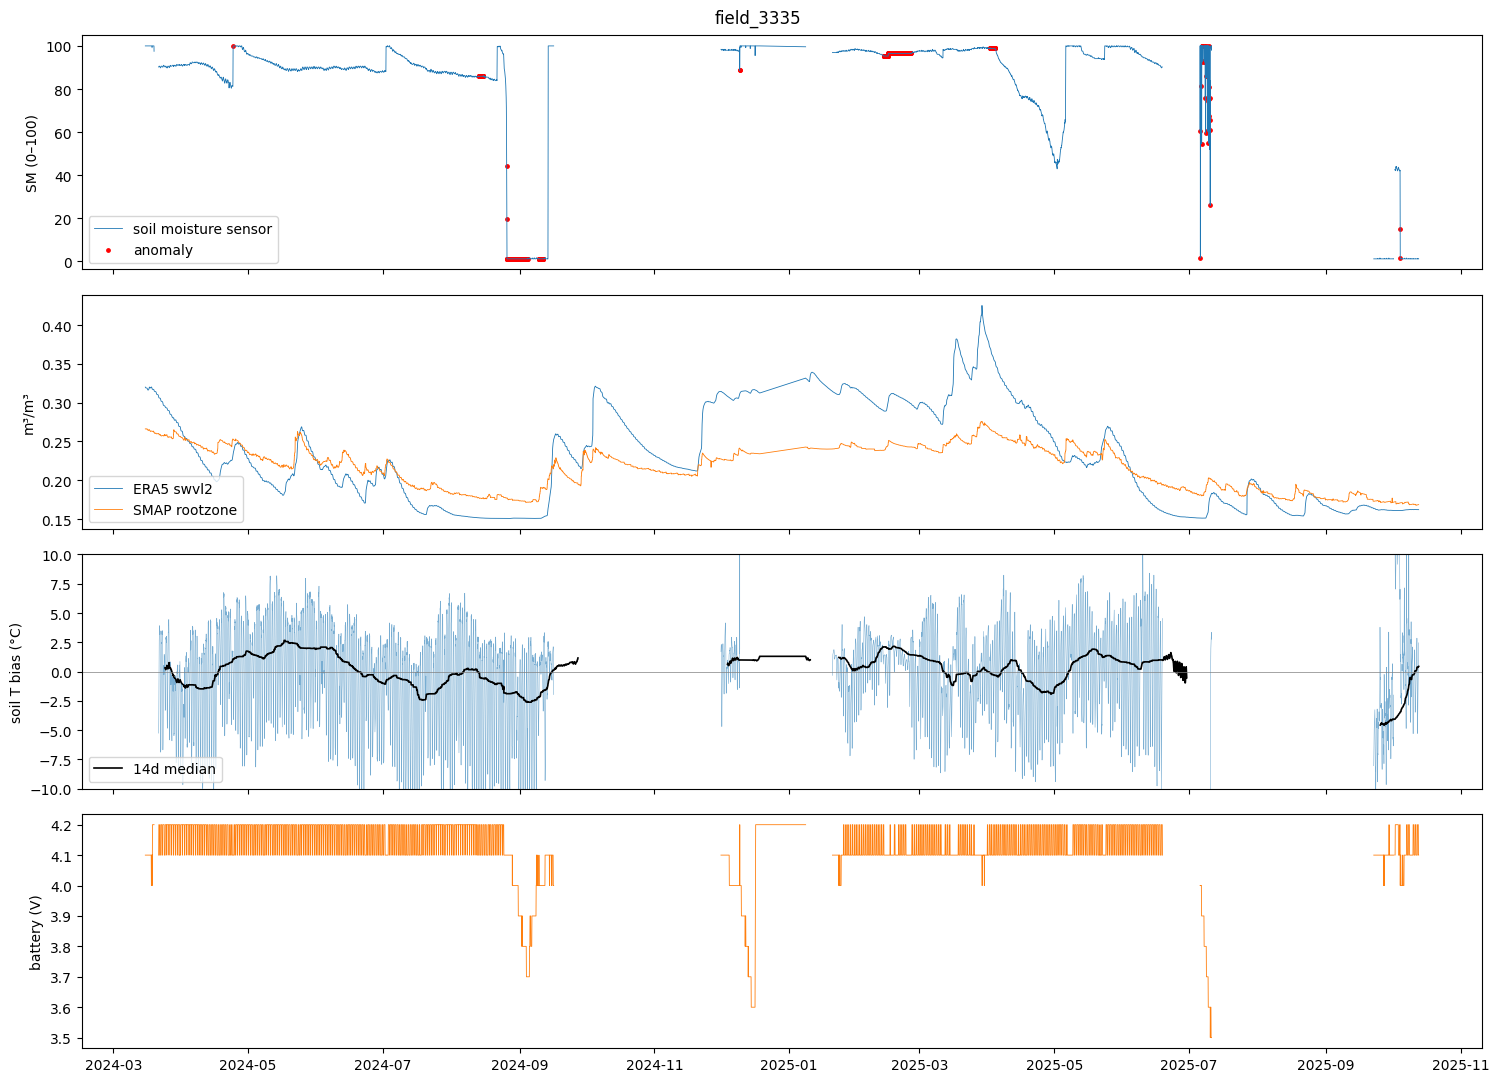

In [102]:
for fid, g in df.groupby("field_id"):
    g = g.set_index("timestamp")
    fig, ax = plt.subplots(4, 1, figsize=(15, 11), sharex=True)
    fig.suptitle(fid)

    ax[0].plot(g[SM], lw=.6, label="soil moisture sensor")
    bad = g["anom_sm_any"]
    ax[0].scatter(g.index[bad], g.loc[bad, SM], s=6, c="r", label="anomaly")
    ax[0].set_ylabel("SM (0–100)"); ax[0].legend(loc="lower left")

    ax[1].plot(g["era5_swvl2"], lw=.6, label="ERA5 swvl2")
    ax[1].plot(g["smap_sm_rootzone"], lw=.6, label="SMAP rootzone")
    ax[1].set_ylabel("m³/m³"); ax[1].legend(loc="lower left")

    resid = g[ST] - g["era5_stl1_c"]
    ax[2].plot(resid, lw=.4, alpha=.6)
    ax[2].plot(resid.rolling(24 * 14, min_periods=24 * 3).median(), c="k", lw=1.2, label="14d median")
    ax[2].axhline(0, c="gray", lw=.5); ax[2].set_ylim(-10, 10)
    ax[2].set_ylabel("soil T bias (°C)"); ax[2].legend(loc="lower left")

    ax[3].plot(g["battery_voltage"], lw=.6, c="tab:orange")
    ax[3].set_ylabel("battery (V)")
    plt.tight_layout(); plt.show()

Блок 6. Довідкові дані про ґрунти

In [103]:
SOIL = pd.DataFrame([
 # soil,            FC,    PWP,   porosity, Ksat mm/h, basic infiltration mm/h, source
 ("sand",            0.12,  0.045, 0.437, 210,  40, "FAO-56 T19 mid"),
 ("loamy sand",      0.15,  0.065, 0.437,  61,  30, "FAO-56 T19 mid"),
 ("sandy loam",      0.23,  0.11,  0.453,  26,  20, "FAO-56 T19 mid"),
 ("loam",            0.25,  0.12,  0.463,  13,  13, "FAO-56 T19 mid"),
 ("silt loam",       0.29,  0.15,  0.501,   7,  10, "FAO-56 T19 mid"),
 ("silt",            0.32,  0.17,  0.50,    7,   8, "FAO-56 T19 mid"),
 ("sandy clay loam", 0.26,  0.15,  0.398,   4,   8, "approx"),
 ("clay loam",       0.32,  0.20,  0.464,   2,   6, "approx"),
 ("silty clay loam", 0.335, 0.205, 0.471, 1.5,   4, "FAO-56 T19 mid"),
 ("sandy clay",      0.34,  0.24,  0.430, 1.2,   3, "approx"),
 ("silty clay",      0.36,  0.23,  0.479, 0.9,   2, "FAO-56 T19 mid"),
 ("clay",            0.36,  0.22,  0.475, 0.6,   2, "FAO-56 T19 mid"),
], columns=["soil", "fc", "pwp", "porosity", "ksat_mm_h", "infil_mm_h", "source"]).set_index("soil")
SOIL["taw_mm_per_m"] = (SOIL.fc - SOIL.pwp) * 1000      # доступна вода на 1 м кореневого шару
print(SOIL)

def usda_texture(sand, clay):                            # USDA-трикутник, sand/clay у %
    silt = 100 - sand - clay
    if silt + 1.5 * clay < 15: return "sand"
    if silt + 1.5 * clay >= 15 and silt + 2 * clay < 30: return "loamy sand"
    if (7 <= clay < 20 and sand > 52 and silt + 2 * clay >= 30) or (clay < 7 and silt < 50 and silt + 2 * clay >= 30): return "sandy loam"
    if 7 <= clay < 27 and 28 <= silt < 50 and sand <= 52: return "loam"
    if (silt >= 50 and 12 <= clay < 27) or (50 <= silt < 80 and clay < 12): return "silt loam"
    if silt >= 80 and clay < 12: return "silt"
    if 20 <= clay < 35 and silt < 28 and sand > 45: return "sandy clay loam"
    if 27 <= clay < 40 and 20 < sand <= 45: return "clay loam"
    if 27 <= clay < 40 and sand <= 20: return "silty clay loam"
    if clay >= 35 and sand > 45: return "sandy clay"
    if clay >= 40 and silt >= 40: return "silty clay"
    if clay >= 40 and sand <= 45 and silt < 40: return "clay"
    return "unclassified"

# Текстура полів зі SMAP static (комірка ~9 км, а не поле!)
fs = df.groupby("field_id")[["smap_static_mwrtm_sand", "smap_static_mwrtm_clay",
                             "smap_static_clsm_poros", "smap_static_clsm_wp"]].first()
fs["sand_pct"] = fs.smap_static_mwrtm_sand * 100
fs["clay_pct"] = fs.smap_static_mwrtm_clay * 100
fs["silt_pct"] = 100 - fs.sand_pct - fs.clay_pct
fs["usda_class"] = [usda_texture(s, c) for s, c in zip(fs.sand_pct, fs.clay_pct)]
fs = fs.join(SOIL[["fc", "pwp", "porosity", "ksat_mm_h", "infil_mm_h"]], on="usda_class")
print(fs.round(3))   # порівняйте fc/pwp з SMAP clsm_wp та clsm_poros: вони теж є «еталоном»

                    fc    pwp  porosity  ksat_mm_h  infil_mm_h          source  taw_mm_per_m
soil                                                                                        
sand             0.120  0.045     0.437      210.0          40  FAO-56 T19 mid          75.0
loamy sand       0.150  0.065     0.437       61.0          30  FAO-56 T19 mid          85.0
sandy loam       0.230  0.110     0.453       26.0          20  FAO-56 T19 mid         120.0
loam             0.250  0.120     0.463       13.0          13  FAO-56 T19 mid         130.0
silt loam        0.290  0.150     0.501        7.0          10  FAO-56 T19 mid         140.0
silt             0.320  0.170     0.500        7.0           8  FAO-56 T19 mid         150.0
sandy clay loam  0.260  0.150     0.398        4.0           8          approx         110.0
clay loam        0.320  0.200     0.464        2.0           6          approx         120.0
silty clay loam  0.335  0.205     0.471        1.5           4  FAO-56

Блок 7. Норми води для культур: Kc, ETc, критичний поріг

In [104]:
CROP = pd.DataFrame([
 # crop,       Kc_ini Kc_mid Kc_end root_m  p(MAD)  seasonal ETc, mm
 ("corn",       0.30, 1.20, 0.35, 1.2, 0.55, (500, 800)),
 ("sorghum",    0.30, 1.05, 0.55, 1.3, 0.55, (450, 650)),
 ("wheat",      0.40, 1.15, 0.25, 1.5, 0.55, (450, 650)),
 ("sunflower",  0.35, 1.08, 0.35, 1.1, 0.45, (600, 1000)),
 ("soybean",    0.40, 1.15, 0.50, 0.9, 0.50, (450, 700)),
 ("sugar beet", 0.35, 1.20, 0.70, 1.0, 0.55, (550, 750)),
 ("tomato",     0.60, 1.15, 0.80, 1.0, 0.40, (400, 800)),
 ("potato",     0.50, 1.15, 0.75, 0.5, 0.35, (500, 700)),
], columns=["crop", "kc_ini", "kc_mid", "kc_end", "root_m", "p_mad", "season_etc_mm"]).set_index("crop")

# Календар фенофаз: (посів, початок розвитку, початок mid, початок late, кінець) MM-DD.
# Значення орієнтовні, відредагуйте під ваш регіон.
CAL = {"corn":    ("04-20", "05-20", "07-01", "08-20", "09-30"),
       "sorghum": ("05-10", "06-05", "07-10", "08-25", "10-05")}

def kc_series(ts, crop):
    if crop not in CAL: return pd.Series(np.nan, index=ts.index)
    y = ts.dt.year.astype(str)
    d = [pd.to_datetime(y + "-" + m) for m in CAL[crop]]
    r = CROP.loc[crop]; kc = pd.Series(np.nan, index=ts.index)
    kc[(ts >= d[0]) & (ts < d[1])] = r.kc_ini
    m = (ts >= d[1]) & (ts < d[2])
    kc[m] = r.kc_ini + (r.kc_mid - r.kc_ini) * (ts[m] - d[1][m]).dt.days / (d[2][m] - d[1][m]).dt.days
    kc[(ts >= d[2]) & (ts < d[3])] = r.kc_mid
    m = (ts >= d[3]) & (ts < d[4])
    kc[m] = r.kc_mid + (r.kc_end - r.kc_mid) * (ts[m] - d[3][m]).dt.days / (d[4][m] - d[3][m]).dt.days
    return kc                                         # поза сезоном = NaN

df["kc"] = np.nan
for c in df["crop"].dropna().unique():
    m = df["crop"] == c
    df.loc[m, "kc"] = kc_series(df.loc[m, "timestamp"], c)
df["etc_mm_h"] = df["kc"] * df["et0_mm_h"]            # ETc = Kc * ET0
df["year"] = df["timestamp"].dt.year

season = (df.dropna(subset=["kc"]).groupby(["field_id", "crop", "year"]).agg(
            days=("timestamp", lambda s: s.dt.normalize().nunique()),
            etc_mm=("etc_mm_h", "sum"),
            rain_era5_mm=("p_era5_mm_h", "sum"),
            rain_gauge_mm=(PR, "sum")))
print(season.round(0))
print(CROP["season_etc_mm"])                           # sanity-check проти діапазонів FAO

# Критичний поріг вологості: полив при вичерпанні p·TAW (FAO-56, p коригується під ETc)
def trigger(fid, crop, etc_day=5.0):
    fc, pwp = fs.loc[fid, ["fc", "pwp"]]
    p = float(np.clip(CROP.loc[crop, "p_mad"] + 0.04 * (5 - etc_day), 0.1, 0.8))
    taw = (fc - pwp) * CROP.loc[crop, "root_m"] * 1000
    return dict(field_id=fid, crop=crop, p_adj=round(p, 2), taw_mm=round(taw),
                raw_mm=round(p * taw), theta_trigger=round(fc - p * (fc - pwp), 3))

pairs = df.groupby(["field_id", "crop"]).size().index
print(pd.DataFrame([trigger(f, c) for f, c in pairs]))

# Перенос порога (м³/м³) на шкалу сенсора 0-100 через квантильне зіставлення (ЕКСПЕРИМЕНТАЛЬНО).
# Це припускає монотонний зв'язок сенсора з реальною вологою.
for fid, gg in df.groupby("field_id"):
    ref, sens = gg["era5_swvl2"].dropna(), gg[SM].dropna()
    for c in gg["crop"].dropna().unique():
        th = trigger(fid, c)["theta_trigger"]
        q = (ref < th).mean()
        print(fid, c, f"theta_trigger={th} -> percentile {q:.2f} -> sensor ≈ {sens.quantile(q):.1f}")

                         days  etc_mm  rain_era5_mm  rain_gauge_mm
field_id   crop    year                                           
field_3334 corn    2025   163   676.0         190.0          118.0
           sorghum 2024   148   585.0         276.0          225.0
field_3335 corn    2024   163   698.0         275.0           83.0
                   2025   163   676.0         190.0           76.0
crop
corn           (500, 800)
sorghum        (450, 650)
wheat          (450, 650)
sunflower     (600, 1000)
soybean        (450, 700)
sugar beet     (550, 750)
tomato         (400, 800)
potato         (500, 700)
Name: season_etc_mm, dtype: object
     field_id     crop  p_adj  taw_mm  raw_mm  theta_trigger
0  field_3334     corn   0.55     156      86          0.178
1  field_3334  sorghum   0.55     169      93          0.178
2  field_3335     corn   0.55     156      86          0.178
field_3334 sorghum theta_trigger=0.178 -> percentile 0.29 -> sensor ≈ 75.7
field_3334 corn theta_trigger=0

Блок 8. Довідник типів поливу (для арбітр-логіки)

In [105]:
IRR = pd.DataFrame([
 # system,           efficiency, wetted_fraction, typical_rate_mm_h, note
 ("drip",            0.90, 0.4, 2,  "локальний полив: орієнтуйтесь на сенсор у зоні крапельниці"),
 ("sprinkler",       0.75, 1.0, 10, "норма подачі має бути ≤ infil_mm_h ґрунту, інакше стік; вітер і випаровування"),
 ("surface/furrow",  0.60, 1.0, 30, "великі разові норми, низька ефективність"),
], columns=["system", "efficiency", "wetted_fraction", "typical_rate_mm_h", "note"]).set_index("system")

def gross_irrigation_mm(net_mm, system):               # net -> gross з урахуванням ефективності
    return net_mm / IRR.loc[system, "efficiency"]

def sprinkler_ok(soil_class, system="sprinkler"):
    return IRR.loc[system, "typical_rate_mm_h"] <= SOIL.loc[soil_class, "infil_mm_h"]

Клітинка 0. Налаштування й перевірка залежностей

In [106]:
from pathlib import Path
import json, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60)

# ---------------- КОНФІГ (все, що залежить від відповідей власників даних) ----------------
RANDOM_SEED       = 42
H_LIST            = [24, 48, 72]                    # горизонти прогнозу, год
LABEL_H_DAYS      = {24: 1, 48: 2, 72: 3}           # горизонт у добах для міток
DEAD_SM_THRESHOLD = 10                              # SM < порогу = «мертвий» сенсор
BUFFER_H          = 48                              # буфер навколо відмов, год
POST_GAP_H        = 24                              # скільки годин після розриву не довіряємо сенсору
SENSOR_SHIFT_H    = 0                               # зсув часу сенсорів відносно UTC (див. Проблему 11)
TEST_START        = pd.Timestamp("2025-04-01")
TEST_END          = pd.Timestamp("2025-11-01")
GAP_H             = max(H_LIST)                     # розрив між train і test
FORECAST_MODE     = "noisy"                         # "oracle" | "noisy" (див. Проблему 8)
DECISION_HOUR     = 6                               # година добового рішення (UTC)
MIN_COVERAGE      = 0.4                             # мін. частка не-NaN по кожному полю для ознаки
EVENT_DATE        = pd.Timestamp("2024-10-16")      # подія з CUSUM на 3334
OUT_DIR           = Path("../data/processed")
RUN_LOG           = {}                              # сюди збираємо підсумки

# ---------------- Перевірка, що попередні клітинки виконано ----------------
_need_names = ["SM", "ST", "AT", "AH", "AP", "PR", "fs", "CROP", "CAL", "SOIL", "IRR", "usda_texture", "fcols"]
_miss = [n for n in _need_names if n not in globals()]
assert not _miss, f"Спочатку запустіть клітинки 0–21 ноутбука; бракує: {_miss}"
_need_cols = ["anom_sm_any", "kc", "etc_mm_h", "et0_mm_h", "p_era5_mm_h", "pet_era5_mm_h", "crop",
              "st_vs_era5", "sm_flat_stuck", f"rng_{ST}"]
_miss = [c for c in _need_cols if c not in df.columns]
assert not _miss, f"У df бракує колонок: {_miss}"

df = df.sort_values(["field_id", "timestamp"]).reset_index(drop=True).copy()
assert not df.duplicated(["field_id", "timestamp"]).any()
df["day"] = df["timestamp"].dt.normalize()
for c in ["anom_sm_any", "st_vs_era5", f"rng_{ST}", "sm_flat_stuck"]:
    df[c] = df[c].fillna(False).astype(bool)
print("OK:", df.shape)

OK: (27346, 158)


Проблема 5. Накопичувальні ERA5-змінні не виправлені повністю

In [107]:
# Які колонки накопичувальні? Скидання очікуємо о 01:00 (ERA5-Land).
ERA5_ACC_CANDIDATES = ["era5_tp_mm", "era5_ssrd", "era5_sro", "era5_ssro",
                       "era5_e", "era5_evabs", "era5_evavt", "era5_pev"]
FORCE_ACC = {"era5_tp_mm", "era5_pev", "era5_ssrd"}   # підтверджено на ваших даних раніше

def accumulation_check(d, cols, reset_hour=1):
    hr = d["timestamp"].dt.hour
    rows = []
    for c in cols:
        if c not in d.columns:
            continue
        s = d[c]
        nz = s[s.ne(0) & s.notna()]
        if nz.empty:
            continue
        sign = 1.0 if nz.median() > 0 else -1.0                 # евапорація в ERA5 від'ємна
        step = d.groupby("field_id")[c].diff() * sign
        thr = 0.02 * s.abs().quantile(0.99)
        reset = step < -thr                                     # різке «обнулення»
        rows.append(dict(col=c, n_resets=int(reset.sum()),
                         share_resets_at_01h=round(float((reset & hr.eq(reset_hour)).sum() / max(reset.sum(), 1)), 3)))
    return pd.DataFrame(rows)

acc_report = accumulation_check(df, ERA5_ACC_CANDIDATES)
print(acc_report)       # ПЕРЕВІРТЕ: накопичувальні = share_resets_at_01h близько 1 і n_resets >= ~50
detected = set(acc_report.loc[(acc_report.share_resets_at_01h >= 0.8) & (acc_report.n_resets >= 50), "col"])
ACC_TO_FIX = sorted(detected | (FORCE_ACC & set(df.columns)))
print("Де-акумулюємо:", ACC_TO_FIX)

def deaccumulate(d, col, reset_hour=1):
    inc = d.groupby("field_id")[col].diff()
    is_reset = d["timestamp"].dt.hour.eq(reset_hour)
    inc = inc.where(~is_reset, d[col])                          # о 01:00 значення = приріст за годину
    step = d.groupby("field_id")["timestamp"].diff()
    return inc.where(is_reset | step.eq(pd.Timedelta("1h")))    # не різницюємо через пропуски

# (нова колонка, множник, обрізати знизу нулем)
CONV = {
    "era5_tp_mm": ("p_era5_mm_h",    1.0,       True),    # мм
    "era5_ssrd":  ("era5_ssrd_wm2",  1/3600,    True),    # Дж/м² за год -> Вт/м²
    "era5_sro":   ("era5_sro_mm_h",  1000.0,    True),    # м -> мм
    "era5_ssro":  ("era5_ssro_mm_h", 1000.0,    True),
    "era5_e":     ("era5_e_mm_h",    -1000.0,   False),   # випаровування від'ємне; конденсацію не обрізаємо
    "era5_evabs": ("era5_evabs_mm_h",-1000.0,   False),
    "era5_evavt": ("era5_evavt_mm_h",-1000.0,   False),
    "era5_pev":   ("pet_era5_mm_h",  -1000.0,   True),
}
ACC_DONE = []
for c in ACC_TO_FIX:
    new, k, clip0 = CONV[c]
    inc = deaccumulate(df, c) * k
    df[new] = inc.clip(lower=0) if clip0 else inc
    ACC_DONE.append(c)
df = df.copy()

# Перевірка здорового глузду: радіація вночі ~0, пік вдень
if "era5_ssrd_wm2" in df.columns:
    print(df.groupby(df["timestamp"].dt.hour)["era5_ssrd_wm2"].mean().round(0).to_dict())

# ET0 і ETc перераховуємо; калібрування k_pet лише на train-періоді (без витоку з тесту)
ov = df.loc[df["timestamp"] < TEST_START, ["pet_era5_mm_h", "openmeteo_et0_fao_evapotranspiration"]].dropna()
k_pet = (ov.iloc[:, 1] * ov.iloc[:, 0]).sum() / (ov.iloc[:, 0] ** 2).sum()
df["et0_mm_h"] = df["openmeteo_et0_fao_evapotranspiration"].fillna(k_pet * df["pet_era5_mm_h"])
df["etc_mm_h"] = df["kc"] * df["et0_mm_h"]
RUN_LOG["k_pet"] = round(float(k_pet), 3); RUN_LOG["acc_deaccumulated"] = ACC_DONE
print("k_pet =", round(float(k_pet), 3))

          col  n_resets  share_resets_at_01h
0  era5_tp_mm       400                1.000
1   era5_ssrd      1139                0.999
2    era5_sro       350                1.000
3   era5_ssro      1139                0.999
4      era5_e      1134                1.000
5  era5_evabs      1085                1.000
6  era5_evavt      4070                0.067
7    era5_pev      1137                1.000
Де-акумулюємо: ['era5_e', 'era5_evabs', 'era5_pev', 'era5_sro', 'era5_ssrd', 'era5_ssro', 'era5_tp_mm']
{0: 0.0, 1: 0.0, 2: 0.0, 3: 0.0, 4: 10.0, 5: 59.0, 6: 153.0, 7: 264.0, 8: 387.0, 9: 490.0, 10: 556.0, 11: 578.0, 12: 557.0, 13: 491.0, 14: 395.0, 15: 282.0, 16: 170.0, 17: 77.0, 18: 19.0, 19: 1.0, 20: 0.0, 21: 0.0, 22: 0.0, 23: 0.0}
k_pet = 0.592


Проблема 11. Невідомий часовий пояс сенсорів

In [108]:
def lag_scan(a, b, lags=range(-12, 13)):
    # corr(a(t-L), b(t)); максимум при L>0 означає, що сенсор «випереджає» еталон на L год
    return pd.Series({L: a.shift(L).corr(b) for L in lags})

tz_rows = []
for fid, g in df.groupby("field_id"):
    g = g.set_index("timestamp")
    s_at = lag_scan(g[AT], g["era5_t2m_c"])
    tz_rows.append(dict(field_id=fid, pair="AT vs ERA5 t2m", best_lag_h=int(s_at.idxmax()),
                        corr_best=round(s_at.max(), 3), corr_lag0=round(s_at[0], 3)))
    if "era5_ssrd_wm2" in g.columns and "solar_panel_voltage" in g.columns:
        s_sp = lag_scan(g["solar_panel_voltage"], g["era5_ssrd_wm2"])
        tz_rows.append(dict(field_id=fid, pair="solar_panel vs ERA5 ssrd", best_lag_h=int(s_sp.idxmax()),
                            corr_best=round(s_sp.max(), 3), corr_lag0=round(s_sp[0], 3)))
tz_report = pd.DataFrame(tz_rows)
print(tz_report)
# ПЕРЕВІРТЕ: best_lag_h = 0 (або ±1) -> час вирівняно, SENSOR_SHIFT_H лишаємо 0.
# Якщо в обох полів і обох пар стабільно L != 0 -> поставте SENSOR_SHIFT_H = L у клітинці 0
# і ПЕРЕЗАПУСТІТЬ клітинки Проблем 1, 10, 12 (маски залежать від вирівнювання).

SENSOR_COLS = [c for c in [AT, AH, AP, ST, SM, PR, "dew_point_sensor", "battery_voltage", "solar_panel_voltage"]
               if c in df.columns]
if SENSOR_SHIFT_H != 0 and "_tz_applied" not in globals():
    df[SENSOR_COLS] = df.groupby("field_id")[SENSOR_COLS].shift(SENSOR_SHIFT_H)
    _tz_applied = True
    print(f"Сенсорні колонки зсунуто на {SENSOR_SHIFT_H} год")
RUN_LOG["tz_best_lags"] = tz_report[["field_id", "pair", "best_lag_h"]].to_dict("records")

     field_id                      pair  best_lag_h  corr_best  corr_lag0
0  field_3334            AT vs ERA5 t2m          -2      0.974      0.953
1  field_3334  solar_panel vs ERA5 ssrd          -2      0.755      0.690
2  field_3335            AT vs ERA5 t2m          -2      0.967      0.944
3  field_3335  solar_panel vs ERA5 ssrd          -2      0.715      0.653


Проблема 1 (блокуюча). Мертвий сенсор не відсіюється, sm_clean не чистий

             rows  sm_nan   dead  bad_total  valid
field_id                                          
field_3334  14007   0.064  0.116      0.235  0.716
field_3335  13339   0.326  0.065      0.165  0.522
SM<поріг, що лишились у sm_clean (має бути 0): 0
field_3334
                  start                 end  hours  batt_min
grp                                                         
1   2024-03-07 10:00:00 2024-03-13 07:00:00    142       4.1
3   2024-07-04 04:00:00 2024-07-08 07:00:00    100       4.1
5   2024-07-20 18:00:00 2024-07-28 05:00:00    180       4.0
7   2024-08-09 23:00:00 2024-09-08 14:00:00    712       4.0
9   2024-12-09 15:00:00 2024-12-16 19:00:00    173       4.0
11  2025-01-01 01:00:00 2025-01-02 00:00:00     24       4.0
13  2025-01-04 18:00:00 2025-01-11 03:00:00    154       4.1
15  2025-01-18 11:00:00 2025-01-25 07:00:00    165       4.0
17  2025-02-15 03:00:00 2025-02-27 14:00:00    300       4.1
19  2025-04-26 11:00:00 2025-05-04 08:00:00    190       4.1
21  

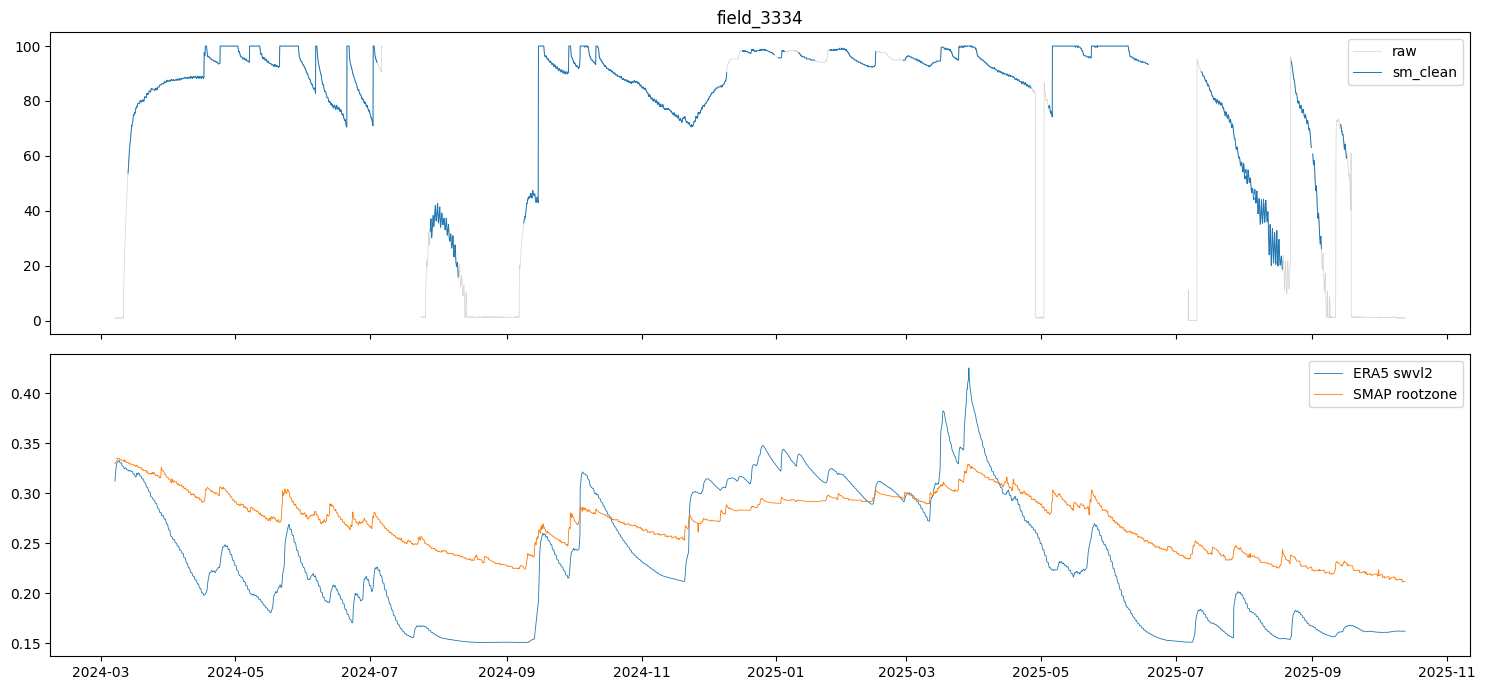

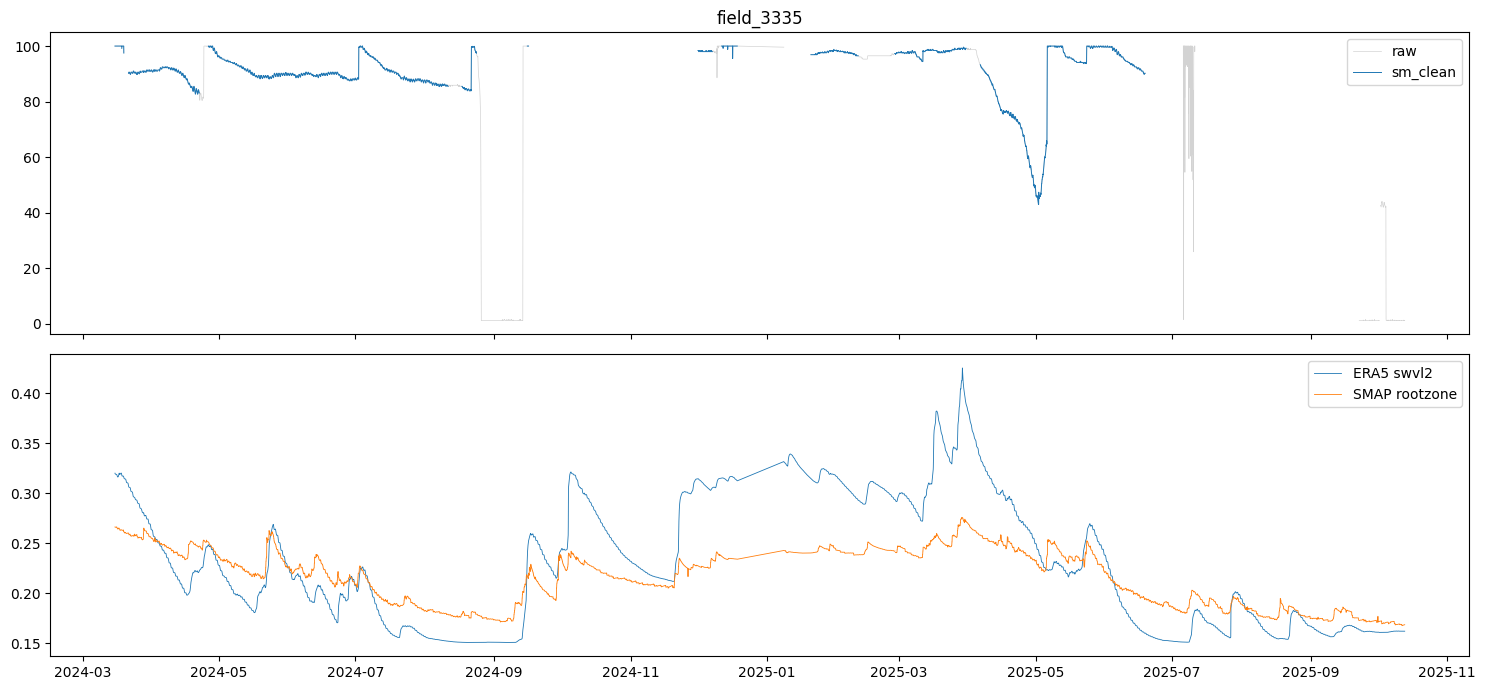

In [109]:
# 1) режим «мертвого» сенсора (≈0–2 при низькій батареї)
df["sm_dead"] = (df[SM] < DEAD_SM_THRESHOLD).fillna(False)

# 2) перші POST_GAP_H годин після розриву в даних
step = df.groupby("field_id")["timestamp"].diff()
gap_start = (step > pd.Timedelta("3h")).astype(float)
df["sm_post_gap"] = (gap_start.groupby(df["field_id"])
                     .transform(lambda s: s.rolling(POST_GAP_H, min_periods=1).max()).astype(bool))

# 3) ядро відмов + буфер ±BUFFER_H (відмови тягнуть за собою нестабільні значення)
df["sm_bad_core"] = (df["anom_sm_any"] | df["sm_dead"]).astype(bool)
buf = (df["sm_bad_core"].astype(float).groupby(df["field_id"])
       .transform(lambda s: s.rolling(2 * BUFFER_H + 1, center=True, min_periods=1).max()).astype(bool))
df["sm_bad"] = buf | df["sm_post_gap"]
df["sm_clean"] = df[SM].where(~df["sm_bad"])
df["is_sm_valid"] = df["sm_clean"].notna()

rep = df.groupby("field_id").agg(rows=("timestamp", "size"),
                                 sm_nan=(SM, lambda s: s.isna().mean()),
                                 dead=("sm_dead", "mean"),
                                 bad_total=("sm_bad", "mean"),
                                 valid=("is_sm_valid", "mean")).round(3)
print(rep)
leak = int(((df[SM] < DEAD_SM_THRESHOLD) & df["is_sm_valid"]).sum())
print("SM<поріг, що лишились у sm_clean (має бути 0):", leak)
assert leak == 0

# Епізоди відмов > 24 год (для перевірки очима)
def episodes(mask, ts, batt):
    grp = (mask != mask.shift()).cumsum()
    t = pd.DataFrame({"grp": grp, "m": mask, "ts": ts, "b": batt})
    return (t[t["m"]].groupby("grp")
              .agg(start=("ts", "min"), end=("ts", "max"), hours=("ts", "size"), batt_min=("b", "min")))
for fid, g in df.groupby("field_id"):
    e = episodes(g["sm_bad"], g["timestamp"], g["battery_voltage"])
    print(fid); print(e[e.hours >= 24])

for fid, g in df.groupby("field_id"):
    fig, ax = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
    ax[0].plot(g["timestamp"], g[SM], lw=.5, c="lightgray", label="raw")
    ax[0].plot(g["timestamp"], g["sm_clean"], lw=.7, label="sm_clean"); ax[0].legend(); ax[0].set_title(fid)
    ax[1].plot(g["timestamp"], g["era5_swvl2"], lw=.6, label="ERA5 swvl2")
    ax[1].plot(g["timestamp"], g["smap_sm_rootzone"], lw=.6, label="SMAP rootzone"); ax[1].legend()
    plt.tight_layout(); plt.show()
# ПЕРЕВІРТЕ на графіку: чи не лишилось «горбів» біля відмов (напр. 3334 у липні–вересні 2024).
# Якщо лишились: збільште BUFFER_H або DEAD_SM_THRESHOLD у клітинці 0 і перезапустіть цю клітинку.
RUN_LOG["sm_valid_share"] = rep["valid"].to_dict()

Проблема 12 (другорядна). Дощомір занижений відносно ERA5

In [110]:
daily_rain = (df.groupby(["field_id", "day"])
                .agg(gauge=(PR, "sum"), era5=("p_era5_mm_h", "sum"),
                     n=("timestamp", "size")).reset_index())
daily_rain = daily_rain[daily_rain["n"] == 24].copy()
daily_rain["gauge_miss"] = (daily_rain["era5"] >= 5) & (daily_rain["gauge"] < 0.5)

summ = daily_rain.groupby("field_id").apply(lambda x: pd.Series({
    "days": len(x),
    "spearman_gauge_vs_era5": x[["gauge", "era5"]].corr(method="spearman").iloc[0, 1],
    "total_ratio_gauge_to_era5": x["gauge"].sum() / x["era5"].sum(),
    "share_rainy_days_missed": x.loc[x.era5 >= 5, "gauge_miss"].mean()})).round(3)
print(summ)

df = df.merge(daily_rain[["field_id", "day", "gauge_miss"]], on=["field_id", "day"], how="left")
df["gauge_miss"] = df["gauge_miss"].fillna(False).astype(bool)
df["rain_mm_h"] = df["p_era5_mm_h"]      # ЄДИНЕ джерело опадів для ознак і міток
# Дощомір (PR) надалі НЕ використовуємо як ознаку: gauge_miss рахується за добовою сумою ERA5,
# тому маска з нього містила б інформацію про майбутні години доби.
RUN_LOG["rain_gauge"] = summ.to_dict()

             days  spearman_gauge_vs_era5  total_ratio_gauge_to_era5  share_rainy_days_missed
field_id                                                                                     
field_3334  582.0                   0.488                      0.742                    0.309
field_3335  554.0                   0.413                      0.463                    0.481


Проблема 10 (другорядна). st_flat на 3334 — фізика чи завислий сенсор

In [111]:
ST_FLAT_MIN_H = 24
ST_STUCK_ERA5_RANGE = 2.0     # якщо ERA5 за цей час змінився ≥2 °C, а сенсор стояв, вважаємо відмовою

def run_table(s, ts, min_len):
    grp = (s != s.shift()).cumsum()
    t = pd.DataFrame({"grp": grp, "v": s, "ts": ts})
    r = t.groupby("grp").agg(v=("v", "first"), start=("ts", "min"), end=("ts", "max"), n=("ts", "size"))
    return r[r["n"] >= min_len]

df["st_stuck"] = False
rows = []
for fid, g in df.groupby("field_id"):
    for _, r in run_table(g[ST], g["timestamp"], ST_FLAT_MIN_H).iterrows():
        m = (g["timestamp"] >= r["start"]) & (g["timestamp"] <= r["end"])
        ref = g.loc[m, "era5_stl1_c"]
        era5_range = ref.max() - ref.min()
        stuck = bool(era5_range >= ST_STUCK_ERA5_RANGE)
        rows.append(dict(field_id=fid, start=r["start"], end=r["end"], hours=int(r["n"]),
                         value=r["v"], era5_range=round(float(era5_range), 2), verdict="stuck" if stuck else "plausible"))
        if stuck:
            df.loc[g.index[m.values], "st_stuck"] = True
st_runs = pd.DataFrame(rows)
print(st_runs.groupby(["field_id", "verdict"])["hours"].agg(["count", "sum"]))
print(st_runs[st_runs.verdict == "stuck"].assign(month=lambda x: x.start.dt.to_period("M"))
              .groupby(["field_id", "month"])["hours"].sum().unstack(0))
# ПЕРЕВІРТЕ: «plausible» довгі серії взимку при низькій ERA5-змінності — норма (мерзлий ґрунт).

bad_st = df["st_stuck"] | df[f"rng_{ST}"] | df["st_vs_era5"]
df["st_clean"] = df[ST].where(~bad_st)
RUN_LOG["st_clean_valid_share"] = df.groupby("field_id")["st_clean"].apply(lambda s: round(s.notna().mean(), 3)).to_dict()

                      count   sum
field_id   verdict               
field_3334 plausible      4   156
           stuck         58  2520
field_3335 plausible      3   111
           stuck         16   579
field_id  field_3334  field_3335
month                           
2024-03         25.0         NaN
2024-10        219.0         NaN
2024-11        385.0         NaN
2024-12        470.0       139.0
2025-01        539.0        69.0
2025-02        297.0       155.0
2025-03        309.0       124.0
2025-04        224.0         NaN
2025-05         26.0        92.0
2025-07         26.0         NaN


Проблема 9. Висновки про дрейф: автокореляція, сезонність, подія жовтня 2024

      field_id                      variable  n_weeks  slope_per_year  ci_lo_year  ci_hi_year   p_hac  tol_per_year  drift_confirmed
0   field_3334   soil_temp vs ERA5 stl1 (°C)       81           1.445       0.205       2.684  0.0224          0.50             True
1   field_3334     air_temp vs ERA5 t2m (°C)       81           0.246      -0.244       0.736  0.3249          0.50            False
2   field_3334     pressure vs ERA5 sp (hPa)       82           0.121       0.041       0.201  0.0029          1.00            False
3   field_3334       humidity vs ERA5 RH (%)       81          -3.587      -6.448      -0.725  0.0140          2.00             True
4   field_3334        SM(rank) vs ERA5 swvl2       72           0.038      -0.174       0.251  0.7248          0.05            False
5   field_3334     SM(rank) vs SMAP rootzone       72           0.144      -0.086       0.374  0.2208          0.05            False
6   field_3334  CONTROL: ERA5 vs SMAP (rank)       85           0.097

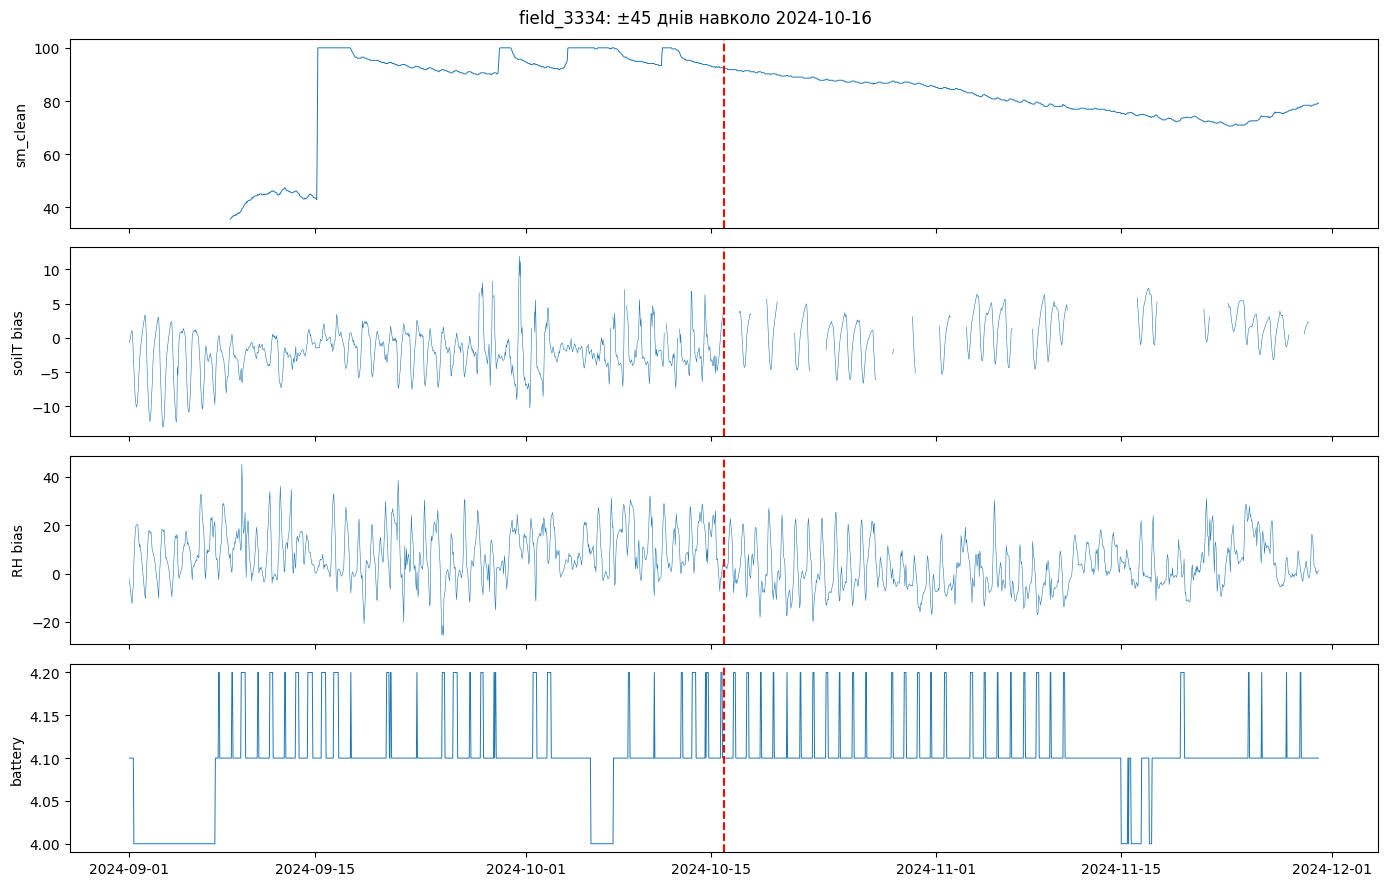

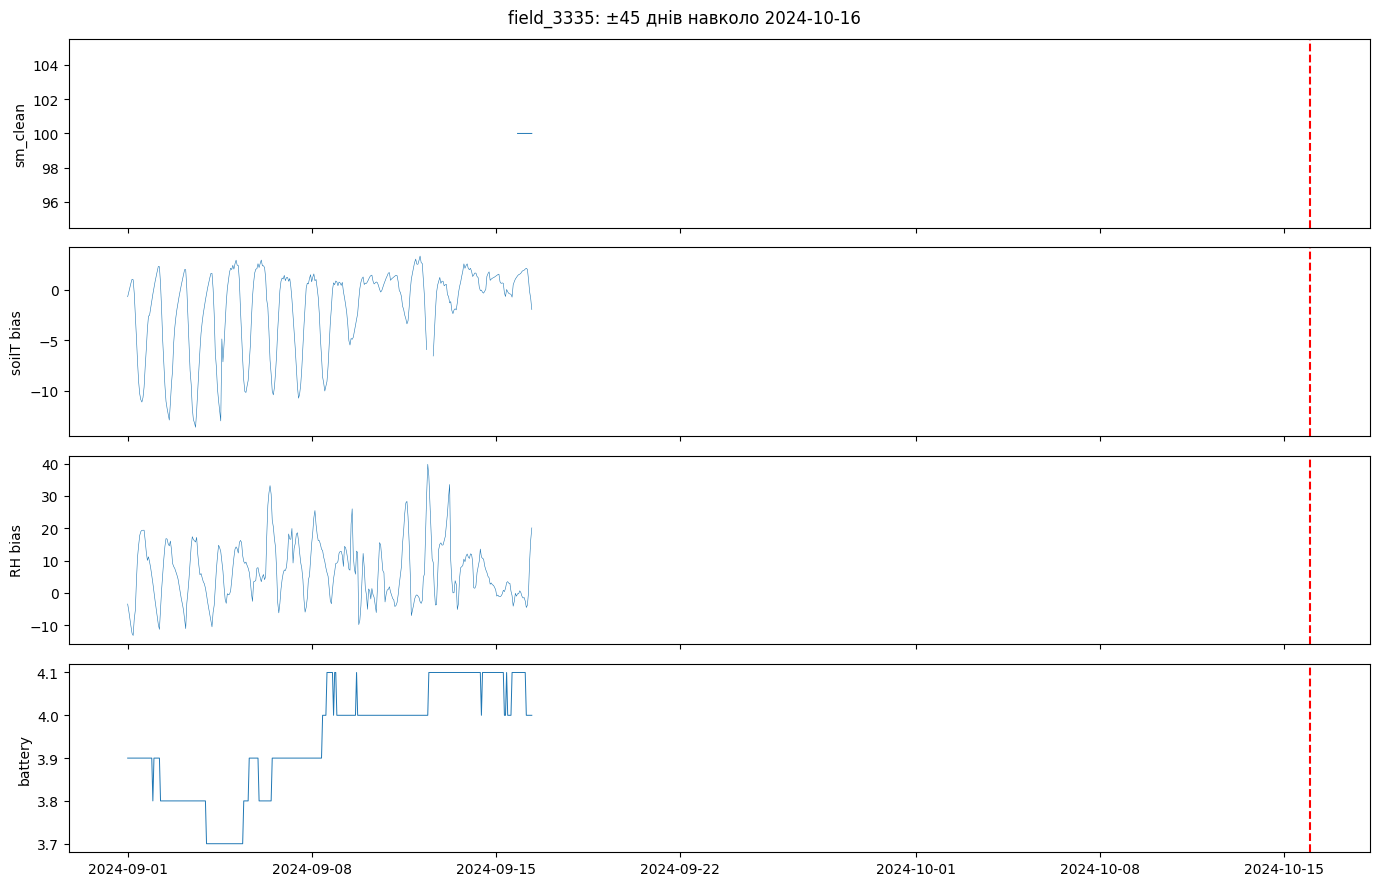

In [112]:
import statsmodels.api as smapi    # pip install statsmodels, якщо немає

def bias_series(g, sensor, ref, rank=False, freq="W"):
    p = g.set_index("timestamp")[[sensor, ref]].dropna()
    if rank:
        p = p.rank(pct=True)                      # різні одиниці -> перцентилі
    return (p[sensor] - p[ref]).resample(freq).median().dropna()

def drift_ols(w):
    # тижневі медіани (менше автокореляції) + річна гармоніка (сезонність) + HAC-похибки
    t_days = (w.index - w.index[0]).days.to_numpy(float)
    ang = 2 * np.pi * t_days / 365.25
    X = np.column_stack([np.ones(len(w)), t_days / 30.0, np.sin(ang), np.cos(ang)])
    res = smapi.OLS(w.to_numpy(float), X).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
    ci = res.conf_int()
    return res.params[1], ci[1][0], ci[1][1], res.pvalues[1], len(w)

# (сенсор, еталон, назва, rank, допуск «практично значущого» дрейфу за рік)
PAIRS2 = [("st_clean", "era5_stl1_c",            "soil_temp vs ERA5 stl1 (°C)", False, 0.5),
          (AT,         "era5_t2m_c",             "air_temp vs ERA5 t2m (°C)",   False, 0.5),
          (AP,         "era5_sp_hpa",            "pressure vs ERA5 sp (hPa)",   False, 1.0),
          (AH,         "era5_relative_humidity", "humidity vs ERA5 RH (%)",     False, 2.0),
          ("sm_clean", "era5_swvl2",             "SM(rank) vs ERA5 swvl2",      True,  0.05),
          ("sm_clean", "smap_sm_rootzone",       "SM(rank) vs SMAP rootzone",   True,  0.05),
          ("era5_swvl2", "smap_sm_rootzone",     "CONTROL: ERA5 vs SMAP (rank)", True, 0.05)]

rows = []
for fid, g in df.groupby("field_id"):
    for s, r, name, rk, tol in PAIRS2:
        w = bias_series(g, s, r, rank=rk, freq="W")
        if len(w) < 20:
            continue
        b, lo, hi, p, n = drift_ols(w)
        per_year = b * 365.25 / 30.0
        rows.append(dict(field_id=fid, variable=name, n_weeks=n, slope_per_year=round(per_year, 3),
                         ci_lo_year=round(lo * 365.25 / 30, 3), ci_hi_year=round(hi * 365.25 / 30, 3),
                         p_hac=round(p, 4), tol_per_year=tol,
                         drift_confirmed=bool((lo > 0 or hi < 0) and abs(per_year) > tol)))
drift2 = pd.DataFrame(rows)
print(drift2.to_string())
# Читати так: дрейф сенсора = confirmed для пари «сенсор vs еталон» І НЕ підтверджений для CONTROL.
# Якщо розходяться самі еталони (CONTROL confirmed), дрейф відносно SMAP/ERA5 не приписуємо сенсору.

# Ступінчаста зміна навколо EVENT_DATE (CUSUM показав 14–20.10.2024 на 3334)
def step_change(g, sensor, ref, date, win=30, rank=False):
    w = bias_series(g, sensor, ref, rank=rank, freq="D")
    a = w[(w.index >= date - pd.Timedelta(days=win)) & (w.index < date)]
    b = w[(w.index >= date) & (w.index < date + pd.Timedelta(days=win))]
    if len(a) < 10 or len(b) < 10:
        return None
    u = stats.mannwhitneyu(a, b, alternative="two-sided")
    return dict(shift=round(float(b.median() - a.median()), 3), p=round(float(u.pvalue), 4),
                n_before=len(a), n_after=len(b))

rows = []
for fid, g in df.groupby("field_id"):
    for s, r, name, rk, _ in PAIRS2[:6]:
        res = step_change(g, s, r, EVENT_DATE, rank=rk)
        if res:
            rows.append(dict(field_id=fid, variable=name, **res))
step_tbl = pd.DataFrame(rows)
print(step_tbl.to_string())

for fid, g in df.groupby("field_id"):
    lo_, hi_ = EVENT_DATE - pd.Timedelta(days=45), EVENT_DATE + pd.Timedelta(days=45)
    gg = g[(g["timestamp"] >= lo_) & (g["timestamp"] < hi_)]
    if gg.empty:
        continue
    fig, ax = plt.subplots(4, 1, figsize=(14, 9), sharex=True); fig.suptitle(f"{fid}: ±45 днів навколо {EVENT_DATE.date()}")
    ax[0].plot(gg["timestamp"], gg["sm_clean"], lw=.7); ax[0].set_ylabel("sm_clean")
    ax[1].plot(gg["timestamp"], gg["st_clean"] - gg["era5_stl1_c"], lw=.4); ax[1].set_ylabel("soilT bias")
    ax[2].plot(gg["timestamp"], gg[AH] - gg["era5_relative_humidity"], lw=.4); ax[2].set_ylabel("RH bias")
    ax[3].plot(gg["timestamp"], gg["battery_voltage"], lw=.7); ax[3].set_ylabel("battery")
    for a_ in ax: a_.axvline(EVENT_DATE, c="r", ls="--")
    plt.tight_layout(); plt.show()
RUN_LOG["drift_confirmed"] = drift2.loc[drift2.drift_confirmed, ["field_id", "variable"]].to_dict("records")

Проблема 7. Культура збігається з роком (на 3334)

In [113]:
xt = (df.assign(year=df["timestamp"].dt.year)
        .groupby(["field_id", "crop", "year"]).size().unstack("year"))
print(xt)     # 3334: sorghum=2024, corn=2025 -> `crop` як ознака еквівалентна «року»

# Замість назви культури використовуємо її фізику: Kc, глибину коренів, частку сезону
def phenology(ts, crop, zr_min=0.3):
    nan = pd.Series(np.nan, index=ts.index)
    if crop not in CAL:
        return nan, nan
    y = ts.dt.year.astype(str)
    d = [pd.to_datetime(y + "-" + m) for m in CAL[crop]]
    in_season = (ts >= d[0]) & (ts <= d[4])
    frac = ((ts - d[0]).dt.days / (d[4] - d[0]).dt.days).where(in_season)
    grow = ((ts - d[0]).dt.days / (d[2] - d[0]).dt.days).clip(0, 1)           # коріння росте до початку mid
    zr = (zr_min + (CROP.loc[crop, "root_m"] - zr_min) * grow).where(in_season)
    return zr, frac

df["zr_m"] = np.nan; df["season_frac"] = np.nan
for c in df["crop"].dropna().unique():
    m = df["crop"] == c
    zr, fr = phenology(df.loc[m, "timestamp"], c)
    df.loc[m, "zr_m"] = zr; df.loc[m, "season_frac"] = fr

df["fc_field"]  = df["field_id"].map(fs["fc"]);  df["pwp_field"] = df["field_id"].map(fs["pwp"])
df["taw_mm"]    = (df["fc_field"] - df["pwp_field"]) * df["zr_m"] * 1000
df = df.drop(columns=["fc_field", "pwp_field"])        # самі fc/pwp константні по полю -> не ознаки

def check_category_overlap(train, test, col="crop"):
    a, b = set(train[col].dropna()), set(test[col].dropna())
    print(f"{col}: test-only категорії (модель їх не бачила): {sorted(b - a)}")
check_category_overlap(df[df.timestamp < TEST_START - pd.Timedelta(hours=GAP_H)],
                       df[(df.timestamp >= TEST_START) & (df.timestamp < TEST_END)])
# `crop` у модель НЕ подаємо (див. чорний список у Проблемі 4); культуру несуть kc, zr_m, taw_mm, season_frac.

year                  2024    2025
field_id   crop                   
field_3334 corn        NaN  6840.0
           sorghum  7167.0     NaN
field_3335 corn     6677.0  6662.0
crop: test-only категорії (модель їх не бачила): []


Проблема 6. Таргет майже без динаміки: цілі, насичення, бейслайни

In [114]:
grp = df.groupby("field_id")
df["sm_saturated"] = (df["sm_clean"] >= 99.9).astype(float).where(df["sm_clean"].notna())   # цензурування на 100

for H in H_LIST:
    fut = grp["sm_clean"].shift(-H)
    df[f"y_sm_h{H}"]   = fut.where(df["sm_clean"].notna())            # валідні і «зараз», і «через H год»
    df[f"y_dsm_h{H}"]  = df[f"y_sm_h{H}"] - df["sm_clean"]            # приріст: інформативніший за рівень біля насичення
    df[f"y_sat_h{H}"]  = (df[f"y_sm_h{H}"] >= 99.9).astype(float).where(df[f"y_sm_h{H}"].notna())

rows = []
for fid, g in df.groupby("field_id"):
    for H in H_LIST:
        y, x = g[f"y_sm_h{H}"], g["sm_clean"]
        m = y.notna()
        rows.append(dict(field_id=fid, H=H, n=int(m.sum()), y_std=y[m].std(),
                         delta_std=(y - x)[m].std(),
                         persistence_rmse=float(np.sqrt(((y - x)[m] ** 2).mean())),
                         share_saturated=float((y[m] >= 99.9).mean()),
                         corr_with_era5_swvl2=float(y[m].corr(g.loc[m, "era5_swvl2"]))))
dyn = pd.DataFrame(rows).round(3)
print(dyn)
# Модель має бити persistence_rmse (прогноз «як зараз»); якщо persistence_rmse ≈ y_std, сигналу мало.
# Додатково порівнюйте з клімато-бейслайном за train-період і з ERA5 swvl2 як допоміжним таргетом.
RUN_LOG["target_dynamics"] = dyn.to_dict("records")

     field_id   H     n   y_std  delta_std  persistence_rmse  share_saturated  corr_with_era5_swvl2
0  field_3334  24  9713  17.885      4.201             4.203            0.154                 0.525
1  field_3334  48  9449  17.699      5.968             5.974            0.158                 0.513
2  field_3334  72  9202  17.519      7.171             7.187            0.159                 0.501
3  field_3335  24  6735   9.355      2.723             2.723            0.073                 0.175
4  field_3335  48  6519   9.431      4.326             4.326            0.066                 0.146
5  field_3335  72  6326   9.495      5.760             5.761            0.061                 0.113


Проблема 8. Припущення «ідеального прогнозу»

In [115]:
def future_sum(frame, col, h):
    # сума col за наступні h годин (t+1..t+h) у межах поля
    return frame.groupby("field_id")[col].transform(
        lambda x: x.iloc[::-1].rolling(h, min_periods=h).sum().iloc[::-1].shift(-1))

def noisy_forecast_values(true, lead_h, rng):
    """Імітація помилок прогнозу опадів: лог-нормальний шум, що росте з горизонтом,
    пропуски дощів і хибні тривоги. Параметри ОРІЄНТОВНІ, налаштуйте за можливості під реальні дані."""
    true = np.asarray(true, dtype=float)
    lead = np.broadcast_to(np.asarray(lead_h, dtype=float), true.shape)
    sigma = 0.35 + 0.15 * (lead / 24.0 - 1.0)
    fc = true * rng.lognormal(mean=-0.5 * sigma ** 2, sigma=sigma)
    p_miss = 0.10 + 0.05 * (lead / 24.0 - 1.0)
    fc = np.where((rng.random(true.shape) < p_miss) & (true >= 2), 0.0, fc)
    false_alarm = (rng.random(true.shape) < 0.03) & (true < 0.2)
    return np.where(false_alarm, rng.gamma(2.0, 2.0, size=true.shape), fc)

rng_fc = np.random.default_rng(RANDOM_SEED)
for h in H_LIST:
    true_h = future_sum(df, "p_era5_mm_h", h)
    df[f"rain_true_next{h}h"] = true_h                                  # ТІЛЬКИ для оцінки; не ознака
    if FORECAST_MODE == "oracle":
        df[f"rain_fc_next{h}h"] = true_h
    else:
        df[f"rain_fc_next{h}h"] = noisy_forecast_values(true_h.to_numpy(), h, rng_fc)
df = df.copy()
print("Режим прогнозу:", FORECAST_MODE)
# Увага: шум незалежний по рядках; для суворішої оцінки бажано шум на рівні доби.
# Найчесніше: підставити реальні архівні прогнози (напр. Historical Forecast API Open-Meteo)
# ПЕРЕВІРТЕ їх доступність і замініть rain_fc_next*h на них.
RUN_LOG["forecast_mode"] = FORECAST_MODE

Режим прогнозу: noisy


Проблема 2 (блокуюча). Немає міток поливу: мітки з водного балансу FAO-56

In [116]:
# Припущення (зафіксуйте в документації; ПЕРЕВІРТЕ значення з вашим агрономом):
PEFF_MIN_MM = 2.0      # дощ менше 2 мм/добу не вважаємо ефективним
PEFF_COEF   = 0.8      # ефективна частка дощу
SYSTEMS = {"sprinkler": dict(p_factor=1.0, eff=0.75),
           "drip":      dict(p_factor=0.8, eff=0.90)}   # крапельне: полив раніше (менша допустима деплеція)

sum24 = lambda s: s.sum(min_count=24)       # NaN, якщо у добі менше 24 валідних годин
daily = (df.groupby(["field_id", "day"])
           .agg(crop=("crop", "first"), et0=("et0_mm_h", sum24), rain=("p_era5_mm_h", sum24),
                etc=("etc_mm_h", sum24), zr=("zr_m", "mean"))
           .reset_index())

def _project(D0, etc_seq, peff_seq, taw_i):
    D_ = D0
    for e_, p_ in zip(etc_seq, peff_seq):
        D_ = min(max(D_ + e_ - p_, 0.0), taw_i)
    return D_

def build_labels(daily_f, fc_, pwp_, system, mode, seed=0):
    prm = SYSTEMS[system]; rng_ = np.random.default_rng(seed)
    d = daily_f.sort_values("day").reset_index(drop=True)
    n = len(d)
    etc  = d["etc"].to_numpy(float);  rain = d["rain"].to_numpy(float)
    zr   = d["zr"].to_numpy(float);   pm = d["crop"].map(CROP["p_mad"]).to_numpy(float)
    ok = np.isfinite(etc) & np.isfinite(rain) & np.isfinite(zr) & np.isfinite(pm)
    taw = (fc_ - pwp_) * zr * 1000.0
    raw = np.clip(pm + 0.04 * (5.0 - etc), 0.1, 0.8) * prm["p_factor"] * taw      # RAW = p·TAW
    peff_true = np.where(rain > PEFF_MIN_MM, PEFF_COEF * rain, 0.0)

    # «Ідеальний менеджер»: поливає до польової місткості, коли деплеція ≥ RAW (синтетичні події)
    D_morn = np.full(n, np.nan); irr = np.zeros(n); state = 0.0
    for i in range(n):
        if not ok[i]:
            state = 0.0                                  # поза сезоном/розрив: початок з польової місткості
            continue
        D_morn[i] = state
        if state >= raw[i]:
            irr[i] = state; state = 0.0
        state = min(max(state + etc[i] - peff_true[i], 0.0), taw[i])

    out = {"day": d["day"], "D_morn_mm": D_morn, "raw_mm": np.where(ok, raw, np.nan),
           "taw_mm": np.where(ok, taw, np.nan), "irr_synth_mm": np.where(ok, irr, np.nan)}
    for H, k in LABEL_H_DAYS.items():
        act = np.full(n, None, dtype=object); need = np.full(n, np.nan)
        for i in range(n):
            if (not ok[i]) or (i + k > n) or (not ok[i:i + k].all()):
                continue
            r_true = rain[i:i + k]
            r_fc = r_true if mode == "oracle" else noisy_forecast_values(r_true, 24.0 * np.arange(1, k + 1), rng_)
            pe_fc = np.where(r_fc > PEFF_MIN_MM, PEFF_COEF * r_fc, 0.0)
            d_rain = _project(D_morn[i], etc[i:i + k], pe_fc, taw[i])           # з прогнозованим дощем
            d_dry  = _project(D_morn[i], etc[i:i + k], np.zeros(k), taw[i])     # без дощу
            if d_rain >= raw[i]:
                act[i] = "irrigate"; need[i] = d_rain / prm["eff"]              # брутто з ефективністю системи
            elif d_dry >= raw[i]:
                act[i] = "postpone"                                             # без дощу довелось би поливати
            else:
                act[i] = "no_action"
        out[f"act_h{H}"] = act; out[f"gross_need_mm_h{H}"] = need
    return pd.DataFrame(out)

parts = []
for fid, g0 in daily.groupby("field_id"):
    full = pd.date_range(g0["day"].min(), g0["day"].max(), freq="D")
    gd = g0.set_index("day").reindex(full).rename_axis("day").reset_index()     # безперервні доби
    fc_, pwp_ = float(fs.loc[fid, "fc"]), float(fs.loc[fid, "pwp"])
    for system in SYSTEMS:
        res = {m: build_labels(gd, fc_, pwp_, system, m, seed=RANDOM_SEED) for m in ("oracle", "noisy")}
        base = res["oracle"][["day", "D_morn_mm", "raw_mm", "taw_mm", "irr_synth_mm"]].copy()
        for H in LABEL_H_DAYS:
            base[f"act_h{H}_oracle"] = res["oracle"][f"act_h{H}"]
            base[f"act_h{H}_noisy"]  = res["noisy"][f"act_h{H}"]
            base[f"act_h{H}"]        = base[f"act_h{H}_{FORECAST_MODE}"]
            base[f"gross_need_mm_h{H}"] = res[FORECAST_MODE][f"gross_need_mm_h{H}"]
        base["field_id"] = fid; base["system"] = system
        parts.append(base)
decisions = pd.concat(parts, ignore_index=True)

print(decisions.groupby(["field_id", "system"])["act_h48"].value_counts().unstack(fill_value=0))
for H in LABEL_H_DAYS:                                   # наскільки помилки прогнозу змінюють рішення
    chk = decisions.dropna(subset=[f"act_h{H}_oracle", f"act_h{H}_noisy"])
    print(f"H={H}: частка рішень, що змінились oracle->noisy:",
          chk.groupby("system").apply(lambda x: (x[f"act_h{H}_oracle"] != x[f"act_h{H}_noisy"]).mean()).round(3).to_dict())
print("sprinkler_ok по полях (швидкість подачі ≤ інфільтрації):",
      {f: bool(sprinkler_ok(fs.loc[f, "usda_class"])) for f in fs.index})

# Добовий датасет рішень: снапшот ознак о DECISION_HOUR + мітки
snap = df[df["timestamp"].dt.hour == DECISION_HOUR]
decision_ds = snap.merge(decisions, on=["field_id", "day"], how="inner")
print("decision_ds:", decision_ds.shape)
RUN_LOG["label_counts_h48"] = decisions["act_h48"].value_counts(dropna=True).to_dict()
# УВАГА: це синтетичний ЕТАЛОН для оцінки шару рішень, а не фактичні поливи.

act_h48               irrigate  no_action  postpone
field_id   system                                  
field_3334 drip             38        270         1
           sprinkler        32        275         2
field_3335 drip             44        279         1
           sprinkler        36        287         1
H=24: частка рішень, що змінились oracle->noisy: {'drip': 0.002, 'sprinkler': 0.0}
H=48: частка рішень, що змінились oracle->noisy: {'drip': 0.0, 'sprinkler': 0.002}
H=72: частка рішень, що змінились oracle->noisy: {'drip': 0.005, 'sprinkler': 0.006}
sprinkler_ok по полях (швидкість подачі ≤ інфільтрації): {'field_3334': True, 'field_3335': True}
decision_ds: (2276, 208)


Проблема 4 (блокуюча). Витік через ознаки та ID-проксі

In [117]:
QC_COLS = set(fcols) | {"anom_sm_any", "anom_iforest", "sm_dead", "sm_post_gap", "sm_bad_core", "sm_bad",
                        "is_sm_valid", "st_stuck", "gauge_miss", "duplicate_timestamp",
                        "missing_sensor_record", "any_quality_flag"}

def build_blacklist(frame):
    bl = {"field_id", "station_id", "latitude", "longitude", "crop", "year", "date", "day", "timestamp",
          "smap_timestamp", "source_file", "system",
          "battery_voltage", "solar_panel_voltage",                  # проксі режиму відмови
          SM, ST, PR,                                                # сирі сенсори -> *_clean / ERA5
          "era5_tp", "era5_stl1", "era5_stl2", "era5_stl3", "era5_stl4", "era5_t2m", "era5_d2m", "era5_sp",  # дублі Кельвін/Па
          "D_morn_mm", "raw_mm", "taw_mm_daily", "irr_synth_mm"}     # вихід симулятора міток
    bl |= set(ACC_DONE)                                              # сирі накопичувальні
    bl |= {c for c in frame.columns if c.startswith(("smap_static_", "era5_grid_", "smap_grid_"))}   # ID поля
    bl |= {c for c in frame.columns if c.startswith(("y_", "act_", "gross_need_", "rain_true_", "has_", "flag_"))}
    bl |= {c for c in QC_COLS if c in frame.columns}
    return bl

def select_features(frame, min_cov=MIN_COVERAGE):
    bl = build_blacklist(frame)
    num = [c for c in frame.select_dtypes(include=[np.number, "bool"]).columns if c not in bl]
    cov = frame.groupby("field_id")[num].apply(lambda x: x.notna().mean()).min()     # найгірше покриття по полях
    keep = [c for c in num if cov[c] >= min_cov and frame[c].nunique(dropna=True) > 1]
    dropped = sorted(set(num) - set(keep))
    return keep, cov, dropped

FEATURES_HOURLY, cov_h, dropped_h = select_features(df)
FEATURES_DAILY,  cov_d, dropped_d = select_features(decision_ds)
print("Ознак (hourly):", len(FEATURES_HOURLY), "| (daily):", len(FEATURES_DAILY))
print("Відкинуто через покриття/сталість (hourly):", dropped_h)
print("Покриття найважливіших:", cov_h[[c for c in ["sm_clean", "st_clean", "openmeteo_et0_fao_evapotranspiration"] if c in cov_h.index]].round(2).to_dict())

assert not ({"battery_voltage", "solar_panel_voltage", SM, ST, PR} & set(FEATURES_HOURLY))
assert not any(c.startswith(("smap_static_", "era5_grid_")) for c in FEATURES_HOURLY)
assert not (set(ACC_DONE) & set(FEATURES_HOURLY))
assert not any(c.startswith(("y_", "act_", "rain_true_")) for c in FEATURES_HOURLY)
# ПЕРЕВІРТЕ: в FEATURES_HOURLY є rain_fc_next*h (не rain_true_*), st_clean, sm_clean, kc, etc_mm_h, taw_mm.
# Примітка: ERA5-Land має затримку ~5 діб, для продакшену реанлізні ознаки доведеться замінити прогнозними.
RUN_LOG["n_features"] = {"hourly": len(FEATURES_HOURLY), "daily": len(FEATURES_DAILY)}

Ознак (hourly): 61 | (daily): 61
Відкинуто через покриття/сталість (hourly): ['openmeteo_direct_radiation', 'openmeteo_et0_fao_evapotranspiration', 'openmeteo_global_tilted_irradiance', 'openmeteo_precipitation', 'openmeteo_rain', 'openmeteo_relative_humidity_2m', 'openmeteo_snowfall', 'openmeteo_soil_moisture_0_to_7cm', 'openmeteo_soil_moisture_7_to_28cm', 'openmeteo_soil_temperature_0_to_7cm', 'openmeteo_soil_temperature_7_to_28cm', 'openmeteo_temperature_2m', 'openmeteo_terrestrial_radiation', 'openmeteo_total_column_integrated_water_vapour', 'openmeteo_vapour_pressure_deficit', 'openmeteo_wet_bulb_temperature_2m', 'openmeteo_wind_direction_100m', 'openmeteo_wind_direction_10m', 'openmeteo_wind_speed_100m', 'openmeteo_wind_speed_10m', 'smap_1km_surface_soil_moisture']
Покриття найважливіших: {'sm_clean': 0.52, 'st_clean': 0.6, 'openmeteo_et0_fao_evapotranspiration': 0.35}


Проблема 3 (блокуюча). Схема time-based валідації і мало валідних даних

In [118]:
FOLDS = [("2025-04-01", "2025-06-15"), ("2025-06-15", "2025-08-15"), ("2025-08-15", "2025-11-01")]
MIN_TEST_ROWS = 500

def time_folds(frame, folds=FOLDS, gap_h=GAP_H, ts_col="timestamp"):
    """Розширюване вікно: train < початок тесту − gap; test = [a, b)."""
    ts = frame[ts_col]
    for a, b in folds:
        a, b = pd.Timestamp(a), pd.Timestamp(b)
        tr = frame.index[ts < a - pd.Timedelta(hours=gap_h)]
        te = frame.index[(ts >= a) & (ts < b)]
        assert ts.loc[tr].max() + pd.Timedelta(hours=gap_h) <= ts.loc[te].min()
        yield (str(a.date()), str(b.date())), tr, te

def main_split(frame, ts_col="timestamp"):
    (_, tr, te), = list(time_folds(frame, [(str(TEST_START.date()), str(TEST_END.date()))], GAP_H, ts_col))
    return tr, te

def lofo_time_split(frame, test_field, t0=TEST_START, gap_h=GAP_H):
    """Train: інше поле до t0−gap; test: це поле після t0 (для оцінки перенесення між полями)."""
    ts = frame["timestamp"]
    tr = frame.index[(frame["field_id"] != test_field) & (ts < t0 - pd.Timedelta(hours=gap_h))]
    te = frame.index[(frame["field_id"] == test_field) & (ts >= t0)]
    return tr, te

def fit_target_scaler(frame, train_idx, col):
    """Статистики лише з train -> без витоку; застосовуйте до train і test однаково."""
    return frame.loc[train_idx].groupby("field_id")[col].agg(["mean", "std"])

# Звіт: скільки валідних таргетів у кожному фолді/полі/горизонті
rep = []
for name, tr, te in time_folds(df):
    for H in H_LIST:
        y = df[f"y_sm_h{H}"]
        for part, idx in (("train", tr), ("test", te)):
            cnt = y.loc[idx].notna().groupby(df.loc[idx, "field_id"]).sum()
            for fid, n in cnt.items():
                rep.append(dict(fold=name, part=part, H=H, field_id=fid, valid_targets=int(n)))
split_report = pd.DataFrame(rep)
print(split_report.pivot_table(index=["fold", "H", "field_id"], columns="part", values="valid_targets"))
weak = split_report[(split_report.part == "test") & (split_report.valid_targets < MIN_TEST_ROWS)]
if len(weak):
    print("УВАГА: мало валідних тестових рядків:\n", weak)

# Те саме для добових міток
rep2 = []
for name, tr, te in time_folds(decision_ds):
    for H in LABEL_H_DAYS:
        for part, idx in (("train", tr), ("test", te)):
            cnt = decision_ds.loc[idx, f"act_h{H}"].notna().groupby([decision_ds.loc[idx, "field_id"], decision_ds.loc[idx, "system"]]).sum()
            for (fid, sysm), n in cnt.items():
                rep2.append(dict(fold=name, part=part, H=H, field_id=fid, system=sysm, labels=int(n)))
print(pd.DataFrame(rep2).pivot_table(index=["fold", "H", "field_id", "system"], columns="part", values="labels"))

# Приклад використання:
# for (name), tr, te in time_folds(df):
#     tr = tr[df.loc[tr, f"y_sm_h48"].notna()]; te = te[df.loc[te, "y_sm_h48"].notna()]   # лише валідні таргети
#     X_tr, y_tr = df.loc[tr, FEATURES_HOURLY], df.loc[tr, "y_sm_h48"]
#     ...  # LightGBM/XGBoost; метрики порівнюйте з persistence з клітинки Проблеми 6
RUN_LOG["splits"] = {"folds": FOLDS, "gap_h": GAP_H, "test": [str(TEST_START.date()), str(TEST_END.date())]}

part                                      test   train
fold                     H  field_id                  
(2025-04-01, 2025-06-15) 24 field_3334  1586.0  6836.0
                            field_3335  1673.0  4966.0
                         48 field_3334  1562.0  6691.0
                            field_3335  1673.0  4797.0
                         72 field_3334  1538.0  6554.0
                            field_3335  1673.0  4628.0
(2025-06-15, 2025-08-15) 24 field_3334   852.0  8420.0
                            field_3335    73.0  6590.0
                         48 field_3334   828.0  8252.0
                            field_3335    49.0  6398.0
                         72 field_3334   804.0  8091.0
                            field_3335    25.0  6229.0
(2025-08-15, 2025-11-01) 24 field_3334   369.0  9272.0
                            field_3335     0.0  6735.0
                         48 field_3334   297.0  9080.0
                            field_3335     0.0  6519.0
          

Проблема 13 (другорядна). Довідкові значення approx і текстура зі SMAP-комірки

In [119]:
# 1) Чутливість порогів до невизначеності довідників
FAO_LOAM = dict(fc_lo=0.20, fc_hi=0.30, pwp_lo=0.07, pwp_hi=0.17)   # ПЕРЕВІРТЕ за FAO-56 Table 19 (loam)

def soil_params(fc_, pwp_, root_m, p_mad, etc_day=5.0):
    p = float(np.clip(p_mad + 0.04 * (5 - etc_day), 0.1, 0.8))
    taw = (fc_ - pwp_) * root_m * 1000
    return dict(fc=fc_, pwp=pwp_, taw_mm=round(taw), raw_mm=round(p * taw), theta_trigger=round(fc_ - p * (fc_ - pwp_), 3))

assert (fs["usda_class"] == "loam").all(), "FAO_LOAM придатний лише для loam; додайте діапазони для інших класів"
rows = []
for fid in fs.index:
    fc_t, pwp_t = float(fs.loc[fid, "fc"]), float(fs.loc[fid, "pwp"])
    smap_wp = float(fs.loc[fid, "smap_static_clsm_wp"])
    scen = {"table_mid": (fc_t, pwp_t),
            "fao_min_taw": (FAO_LOAM["fc_lo"], FAO_LOAM["pwp_hi"]),
            "fao_max_taw": (FAO_LOAM["fc_hi"], FAO_LOAM["pwp_lo"])}
    if smap_wp < fc_t:
        scen["table_fc + smap_wp"] = (fc_t, smap_wp)
    for crop in df.loc[df["field_id"] == fid, "crop"].dropna().unique():
        for sname, (f_, w_) in scen.items():
            rows.append(dict(field_id=fid, crop=crop, scenario=sname,
                             **soil_params(f_, w_, CROP.loc[crop, "root_m"], CROP.loc[crop, "p_mad"])))
sens = pd.DataFrame(rows)
print(sens.to_string())          # розкид theta_trigger і RAW = невизначеність довідника

# 2) Текстура з SoilGrids 250 м (потрібен інтернет; API має ліміт ~5 запитів/хв)
RUN_SOILGRIDS = False             # поставте True, щоб виконати
USE_SOILGRIDS_TEXTURE = False     # True -> перезаписати usda_class/fc/pwp у fs
THICK = pd.Series({"0-5cm": 5, "5-15cm": 10, "15-30cm": 15, "30-60cm": 30, "60-100cm": 40})

def soilgrids_texture(lat, lon):
    import requests
    params = [("lon", lon), ("lat", lat)] + [("property", p) for p in ("sand", "clay", "silt")] \
             + [("depth", d) for d in THICK.index] + [("value", "mean")]
    r = requests.get("https://rest.isric.org/soilgrids/v2.0/properties/query", params=params, timeout=90)
    r.raise_for_status()
    out = {}
    for layer in r.json()["properties"]["layers"]:
        f = layer.get("unit_measure", {}).get("d_factor", 10) or 10
        out[layer["name"]] = {d["label"]: d["values"]["mean"] / f for d in layer["depths"] if d["values"].get("mean") is not None}
    return pd.DataFrame(out)       # у %, рядки = глибини

if RUN_SOILGRIDS:
    sg = {}
    for fid, g in df.groupby("field_id"):
        lat, lon = float(g["latitude"].iloc[0]), float(g["longitude"].iloc[0])
        try:
            tex = soilgrids_texture(lat, lon)
            w = THICK.reindex(tex.index)
            sand, clay = (tex["sand"] * w).sum() / w.sum(), (tex["clay"] * w).sum() / w.sum()
            sg[fid] = dict(sand=sand, clay=clay, silt=100 - sand - clay, usda_class_sg=usda_texture(sand, clay))
        except Exception as e:
            print(fid, "SoilGrids недоступний:", e); sg[fid] = None
        time.sleep(15)
    sg_df = pd.DataFrame({k: v for k, v in sg.items() if v}).T
    print(sg_df.join(fs[["sand_pct", "clay_pct", "usda_class"]], rsuffix="_smap"))
    if USE_SOILGRIDS_TEXTURE and not sg_df.empty:
        fs.loc[sg_df.index, "usda_class"] = sg_df["usda_class_sg"]
        fs[["fc", "pwp", "porosity", "ksat_mm_h", "infil_mm_h"]] = SOIL.loc[fs["usda_class"], ["fc", "pwp", "porosity", "ksat_mm_h", "infil_mm_h"]].values
        print("fs оновлено з SoilGrids; ПЕРЕЗАПУСТІТЬ клітинки Проблем 7 і 2")
RUN_LOG["soil_sensitivity_theta_trigger_range"] = sens.groupby(["field_id", "crop"])["theta_trigger"].agg(["min", "max"]).round(3).reset_index().to_dict("records")

      field_id     crop            scenario    fc       pwp  taw_mm  raw_mm  theta_trigger
0   field_3334  sorghum           table_mid  0.25  0.120000     169      93          0.178
1   field_3334  sorghum         fao_min_taw  0.20  0.170000      39      21          0.183
2   field_3334  sorghum         fao_max_taw  0.30  0.070000     299     164          0.173
3   field_3334  sorghum  table_fc + smap_wp  0.25  0.210736      51      28          0.228
4   field_3334     corn           table_mid  0.25  0.120000     156      86          0.178
5   field_3334     corn         fao_min_taw  0.20  0.170000      36      20          0.183
6   field_3334     corn         fao_max_taw  0.30  0.070000     276     152          0.173
7   field_3334     corn  table_fc + smap_wp  0.25  0.210736      47      26          0.228
8   field_3335     corn           table_mid  0.25  0.120000     156      86          0.178
9   field_3335     corn         fao_min_taw  0.20  0.170000      36      20          0.183

Фінальна клітинка. Перевірки перед передачею, експорт та підсумок

In [120]:
# ---- інваріанти, без яких передавати дані на навчання не можна ----
assert df.loc[df["sm_bad"], "sm_clean"].isna().all()
assert ((df[SM] < DEAD_SM_THRESHOLD) & df["is_sm_valid"]).sum() == 0
# Правильно: спочатку об'єднуємо всі фічі, потім шукаємо перетин із колонками живлення
assert not ({"battery_voltage", "solar_panel_voltage"} & (set(FEATURES_HOURLY) | set(FEATURES_DAILY)))
assert not (set(ACC_DONE) & set(FEATURES_HOURLY))
for H in H_LIST:
    assert df.loc[df["sm_clean"].isna(), f"y_sm_h{H}"].isna().all()
print("Усі інваріанти виконані")

# ---- експорт ----
OUT_DIR.mkdir(parents=True, exist_ok=True)
KEYS = ["field_id", "timestamp", "crop"]
TARGETS = [c for c in df.columns if c.startswith("y_")]
df_model = df[KEYS + FEATURES_HOURLY + TARGETS + ["is_sm_valid"]].copy()

def save(frame, name):
    try:
        frame.to_parquet(OUT_DIR / f"{name}.parquet", index=False)
    except ImportError:                       # немає pyarrow
        frame.to_csv(OUT_DIR / f"{name}.csv", index=False)

save(df_model, "hourly_model_table")
save(decision_ds[KEYS + ["day", "system"] + FEATURES_DAILY + [c for c in decision_ds.columns if c.startswith(("act_", "gross_need_"))]],
     "daily_decision_table")
save(decisions, "decision_labels_daily")
SOIL.to_csv(OUT_DIR / "ref_soil.csv")
CROP.assign(etc_min=CROP["season_etc_mm"].str[0], etc_max=CROP["season_etc_mm"].str[1]).drop(columns="season_etc_mm").to_csv(OUT_DIR / "ref_crop.csv")
IRR.to_csv(OUT_DIR / "ref_irrigation.csv"); fs.to_csv(OUT_DIR / "ref_fields_soil.csv"); sens.to_csv(OUT_DIR / "ref_soil_sensitivity.csv", index=False)
drift2.to_csv(OUT_DIR / "qa_drift.csv", index=False)

meta = dict(config=dict(H_LIST=H_LIST, DEAD_SM_THRESHOLD=DEAD_SM_THRESHOLD, BUFFER_H=BUFFER_H, POST_GAP_H=POST_GAP_H,
                        SENSOR_SHIFT_H=SENSOR_SHIFT_H, FORECAST_MODE=FORECAST_MODE, DECISION_HOUR=DECISION_HOUR,
                        PEFF_MIN_MM=PEFF_MIN_MM, PEFF_COEF=PEFF_COEF, SYSTEMS=SYSTEMS,
                        TEST_START=TEST_START, TEST_END=TEST_END, GAP_H=GAP_H, FOLDS=FOLDS),
            features_hourly=FEATURES_HOURLY, features_daily=FEATURES_DAILY, targets=TARGETS,
            blacklist=sorted(build_blacklist(df)), run_log=RUN_LOG,
            assumptions=["Мітки дій = симуляція водного балансу FAO-56, не фактичні поливи",
                         "Опади для ознак і міток = ERA5 (дощомір ненадійний)",
                         "Текстура ґрунту = SMAP-комірка ~9 км (або SoilGrids, якщо ввімкнено)",
                         "Погода в ознаках = реанліз; у режимі 'noisy' додано імітований шум прогнозу"])
with open(OUT_DIR / "pipeline_meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2, default=str)

# ---- підсумок для висновків у ноутбуці ----
print(json.dumps(RUN_LOG, ensure_ascii=False, indent=2, default=str))

Усі інваріанти виконані
{
  "k_pet": 0.592,
  "acc_deaccumulated": [
    "era5_e",
    "era5_evabs",
    "era5_pev",
    "era5_sro",
    "era5_ssrd",
    "era5_ssro",
    "era5_tp_mm"
  ],
  "tz_best_lags": [
    {
      "field_id": "field_3334",
      "pair": "AT vs ERA5 t2m",
      "best_lag_h": -2
    },
    {
      "field_id": "field_3334",
      "pair": "solar_panel vs ERA5 ssrd",
      "best_lag_h": -2
    },
    {
      "field_id": "field_3335",
      "pair": "AT vs ERA5 t2m",
      "best_lag_h": -2
    },
    {
      "field_id": "field_3335",
      "pair": "solar_panel vs ERA5 ssrd",
      "best_lag_h": -2
    }
  ],
  "sm_valid_share": {
    "field_3334": 0.716,
    "field_3335": 0.522
  },
  "rain_gauge": {
    "days": {
      "field_3334": 582.0,
      "field_3335": 554.0
    },
    "spearman_gauge_vs_era5": {
      "field_3334": 0.488,
      "field_3335": 0.413
    },
    "total_ratio_gauge_to_era5": {
      "field_3334": 0.742,
      "field_3335": 0.463
    },
    "share_r